<a href="https://colab.research.google.com/github/abdulrahmanwalid/Thesis/blob/main/Docking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from openmm.app import *
from openmm import *
from openmm.unit import *

# Load Amber topology/coordinates from your AMBER prep
prmtop = AmberPrmtopFile("/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex.prmtop")
inpcrd = AmberInpcrdFile("/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex.inpcrd")

In [ ]:
# Change only this for each new run
run_name = "DockAD51_Mg_3POV_5"

# Make output directory
os.makedirs(run_name, exist_ok=True)

# File paths
traj_file = os.path.join(run_name, "trajectory.dcd")
log_file = os.path.join(run_name, "simulation.log")

In [ ]:
# ── Build the system ───────────────────────────────────────────
# PME for long-range electrostatics, 1 nm cutoff, HBonds constraints to allow 2 fs timestep
system = prmtop.createSystem(
    nonbondedMethod=PME,
    nonbondedCutoff=1*nanometer,
    constraints=HBonds
)

# ── Cα positional restraints ───────────────────────────────────
# Harmonic restraint binding each Cα to its starting position.
# k is a global parameter so we can release restraints later by setting k=0
# (without rebuilding the system). periodicdistance handles PBC correctly.
restraint = CustomExternalForce("k*periodicdistance(x, y, z, x0, y0, z0)^2")
restraint.addGlobalParameter("k", 100.0*kilocalories_per_mole/angstroms**2)
restraint.addPerParticleParameter("x0")
restraint.addPerParticleParameter("y0")
restraint.addPerParticleParameter("z0")

n_restrained = 0
for atom in prmtop.topology.atoms():
    if atom.residue.name not in ["WAT", "HOH", "Na+", "Cl-", "NA", "CL"] and atom.name == "CA":
        pos = inpcrd.positions[atom.index].value_in_unit(nanometer)
        restraint.addParticle(atom.index, pos)
        n_restrained += 1
system.addForce(restraint)
print(f"Restrained {n_restrained} Cα atoms")

# ── Integrator (thermostat) ────────────────────────────────────
integrator = LangevinIntegrator(300*kelvin, 1/picosecond, 0.002*picoseconds)

# ── Platform & Simulation ──────────────────────────────────────
platform = Platform.getPlatformByName("CUDA")
properties = {"Precision": "mixed"}

simulation = Simulation(prmtop.topology, system, integrator, platform, properties)
simulation.context.setPositions(inpcrd.positions)
if inpcrd.boxVectors is not None:
    simulation.context.setPeriodicBoxVectors(*inpcrd.boxVectors)

# ── Reporters ──────────────────────────────────────────────────
# total steps = heating(60000) + restrained NPT(250000) + free NPT(250000) + production(25000000)
total_steps = 60000 + 250000 + 250000 + 25000000  # = 25,560,000

simulation.reporters.append(DCDReporter(traj_file, 5000))
simulation.reporters.append(
    StateDataReporter(
        log_file, 5000,
        step=True, time=True, potentialEnergy=True, kineticEnergy=True,
        temperature=True, volume=True, density=True,
        progress=True, remainingTime=True, speed=True,
        totalSteps=total_steps, separator="\t"
    )
)

# ── 1. Energy minimization ─────────────────────────────────────
print(f"Output folder: {run_name}")
print("Energy minimization")
simulation.minimizeEnergy()

# ── 2. Gradual heating NVT (5 K → 300 K, 120 ps) ───────────────
# Slowly ramp temperature with restraints active. NVT (no barostat yet).
print("Heating: 5 K → 300 K (120 ps, NVT, restrained)")
simulation.context.setVelocitiesToTemperature(5*kelvin)
for T in range(5, 301, 5):                 # 60 increments × 1000 steps × 2 fs = 120 ps
    integrator.setTemperature(T*kelvin)
    simulation.step(1000)

# ── 3. Switch to NPT: add barostat ─────────────────────────────
# The barostat lets the box volume relax to the correct density at 1 atm.
# reinitialize(preserveState=True) rebuilds the context with the new force,
# keeping current positions and velocities.
system.addForce(MonteCarloBarostat(1*atmosphere, 300*kelvin, 25))
simulation.context.reinitialize(preserveState=True)

# ── 4. NPT equilibration WITH restraints (500 ps) ──────────────
# Box density relaxes while protein backbone stays pinned.
print("Equilibration NPT — restrained (500 ps)")
simulation.step(250000)

# ── 5. Release restraints, NPT equilibration FREE (500 ps) ─────
# Set k=0 to turn off restraints without rebuilding the system.
print("Equilibration NPT — restraints released (500 ps)")
simulation.context.setParameter("k", 0.0)
simulation.step(250000)

# ── 6. Production NPT (50 ns) ──────────────────────────────────
print("Production MD (50 ns, NPT, unrestrained)")
simulation.step(25000000)

print("Simulation finished")
print(f"Trajectory saved to: {traj_file}")
print(f"Log saved to: {log_file}")

Restrained 488 Cα atoms
Output folder: DockAD51_Mg_3POV_5
Energy minimization
Heating: 5 K → 300 K (120 ps, NVT, restrained)
Equilibration NPT — restrained (500 ps)
Equilibration NPT — restraints released (500 ps)
Production MD (50 ns, NPT, unrestrained)
Simulation finished
Trajectory saved to: DockAD51_Mg_3POV_5/trajectory.dcd
Log saved to: DockAD51_Mg_3POV_5/simulation.log


In [ ]:
import pandas as pd
import numpy as np
import MDAnalysis as mda
from MDAnalysis.analysis import rms


def rmsd_for_atomgroups(universes, selection1, selection2=None):
    if not isinstance(universes, list):
        universes = [universes]

    columns = [selection1, *selection2] if selection2 else [selection1]
    dfs = []
    for u in universes:
        u.trajectory[0]
        ref = u
        rmsd_analysis = rms.RMSD(u, ref, select=selection1, groupselections=selection2)
        rmsd_analysis.run()
        df = pd.DataFrame(np.round(rmsd_analysis.results.rmsd[:, 2:], 2), columns=columns)
        dfs.append(df)

    if len(dfs) == 1:
        rmsd_df = dfs[0]
    else:
        min_frames = min(len(df) for df in dfs)
        dfs = [df.iloc[:min_frames] for df in dfs]
        stacked = np.stack([df.values for df in dfs], axis=0)
        rmsd_df = pd.DataFrame(np.round(stacked.mean(axis=0), 2), columns=columns)
        std_df = pd.DataFrame(np.round(stacked.std(axis=0), 2), columns=columns)
        for col in columns:
            rmsd_df[f"{col}_std"] = std_df[col]

    rmsd_df.index.name = "frame"
    return rmsd_df

/home/mk-avid-workstation/miniforge3/envs/MD_science/lib/python3.10/site-packages/MDAnalysis/coordinates/DCD.py:165: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


NameError: name 'plt' is not defined

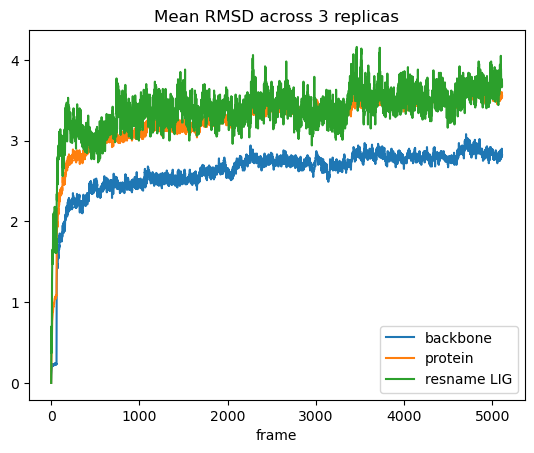

In [ ]:
ligand_name = "LIG"
ptr_top = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex.prmtop"
universes = [
    mda.Universe(ptr_top, f"/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_{i}/trajectory.dcd")
    for i in range(1, 4)
]
rmsd = rmsd_for_atomgroups(universes, "backbone", ["protein", f"resname {ligand_name}"])
rmsd[["backbone", "protein", f"resname {ligand_name}"]].plot(title="Mean RMSD across 3 replicas")
plt.ylabel("RMSD (Å)")

/home/mk-avid-workstation/miniforge3/envs/MD_science/lib/python3.10/site-packages/MDAnalysis/coordinates/DCD.py:165: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


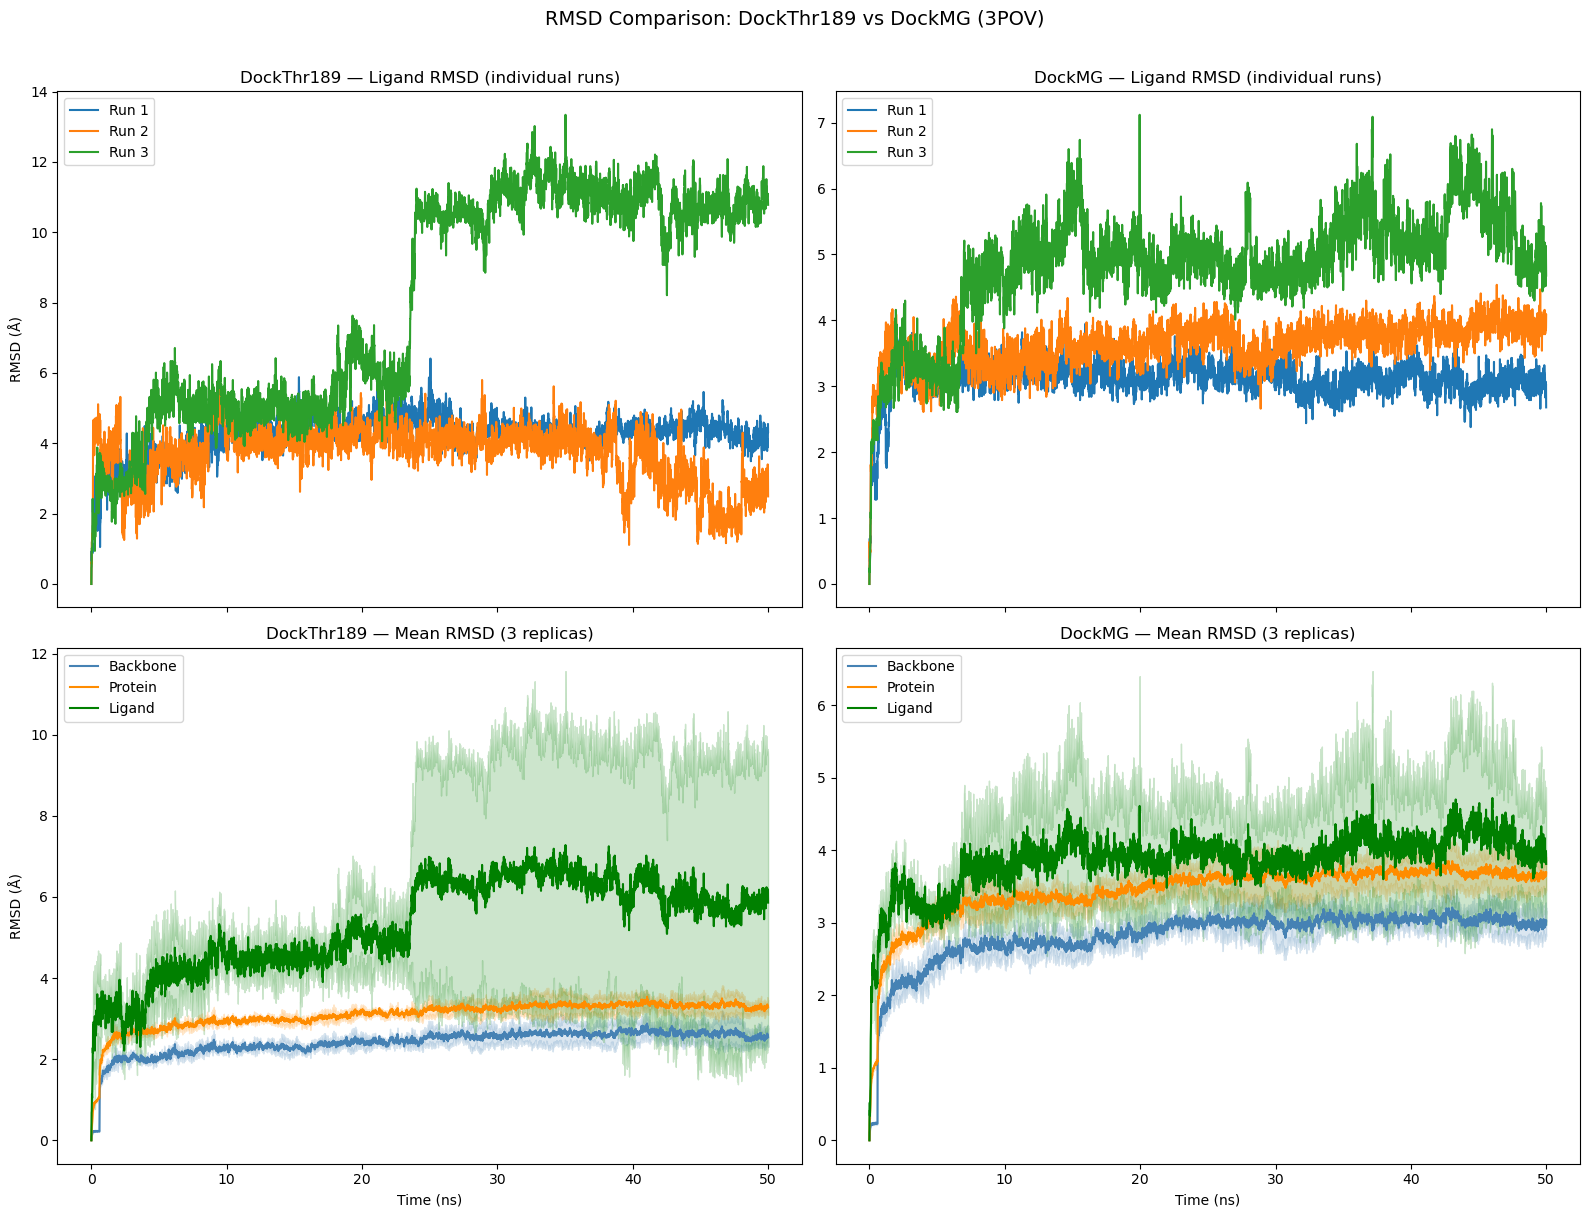

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import MDAnalysis as mda
from MDAnalysis.analysis import rms


def rmsd_for_atomgroups(universes, selection1, selection2=None):
    if not isinstance(universes, list):
        universes = [universes]
    columns = [selection1, *selection2] if selection2 else [selection1]
    dfs = []
    for u in universes:
        u.trajectory[0]
        ref = u
        rmsd_analysis = rms.RMSD(u, ref, select=selection1, groupselections=selection2)
        rmsd_analysis.run()
        df = pd.DataFrame(np.round(rmsd_analysis.results.rmsd[:, 2:], 2), columns=columns)
        dfs.append(df)
    if len(dfs) == 1:
        rmsd_df = dfs[0]
    else:
        min_frames = min(len(df) for df in dfs)
        dfs = [df.iloc[:min_frames] for df in dfs]
        stacked = np.stack([df.values for df in dfs], axis=0)
        rmsd_df = pd.DataFrame(np.round(stacked.mean(axis=0), 2), columns=columns)
        std_df = pd.DataFrame(np.round(stacked.std(axis=0), 2), columns=columns)
        for col in columns:
            rmsd_df[f"{col}_std"] = std_df[col]
    rmsd_df.index.name = "frame"
    return rmsd_df


# --- Config ---
ligand_name = "LIG"
n_frames = 5112
total_ns = 50.0
frame_time_ns = total_ns / n_frames

# --- Topologies & trajectories ---
thr_top = "/home/mk-avid-workstation/MD Sim/3POV/Thr189_3POV/complex.prmtop"
mg_top = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex.prmtop"

thr_trajs = [f"/home/mk-avid-workstation/MD Sim/thr_3POV_{i}/trajectory.dcd" for i in range(1, 4)]
mg_trajs = [
    "/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_1/trajectory.dcd",
    "/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_3/trajectory.dcd",
    "/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_5/trajectory.dcd",
]
# --- Load universes ---
thr_universes = [mda.Universe(thr_top, t) for t in thr_trajs]
mg_universes = [mda.Universe(mg_top, t) for t in mg_trajs]

# --- Compute RMSD per replica ---
sel1 = "backbone"
sel2 = ["protein", f"resname {ligand_name}"]

thr_replicas = [rmsd_for_atomgroups(u, sel1, sel2) for u in thr_universes]
mg_replicas = [rmsd_for_atomgroups(u, sel1, sel2) for u in mg_universes]

# --- Compute averages ---
thr_avg = rmsd_for_atomgroups(thr_universes, sel1, sel2)
mg_avg = rmsd_for_atomgroups(mg_universes, sel1, sel2)

# --- Plot: 2x2 grid ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True)

colors_runs = ["tab:blue", "tab:orange", "tab:green"]
colors_avg = {"backbone": "steelblue", "protein": "darkorange", f"resname {ligand_name}": "green"}
labels_avg = {"backbone": "Backbone", "protein": "Protein", f"resname {ligand_name}": "Ligand"}

# --- Top-left: Thr189 individual runs (ligand only) ---
ax = axes[0, 0]
for i, df in enumerate(thr_replicas):
    t = df.index * frame_time_ns
    ax.plot(t, df[f"resname {ligand_name}"], color=colors_runs[i], label=f"Run {i+1}")
ax.set_ylabel("RMSD (Å)")
ax.set_title("DockThr189 — Ligand RMSD (individual runs)")
ax.legend()

# --- Top-right: DockMG individual runs (ligand only) ---
ax = axes[0, 1]
for i, df in enumerate(mg_replicas):
    t = df.index * frame_time_ns
    ax.plot(t, df[f"resname {ligand_name}"], color=colors_runs[i], label=f"Run {i+1}")
ax.set_title("DockMG — Ligand RMSD (individual runs)")
ax.legend()

# --- Bottom-left: Thr189 average (backbone + protein + ligand) ---
ax = axes[1, 0]
t = thr_avg.index * frame_time_ns
for col in [sel1, "protein", f"resname {ligand_name}"]:
    ax.plot(t, thr_avg[col], color=colors_avg[col], label=labels_avg[col])
    if f"{col}_std" in thr_avg.columns:
        ax.fill_between(t, thr_avg[col] - thr_avg[f"{col}_std"],
                        thr_avg[col] + thr_avg[f"{col}_std"], alpha=0.2, color=colors_avg[col])
ax.set_xlabel("Time (ns)")
ax.set_ylabel("RMSD (Å)")
ax.set_title("DockThr189 — Mean RMSD (3 replicas)")
ax.legend()

# --- Bottom-right: DockMG average (backbone + protein + ligand) ---
ax = axes[1, 1]
t = mg_avg.index * frame_time_ns
for col in [sel1, "protein", f"resname {ligand_name}"]:
    ax.plot(t, mg_avg[col], color=colors_avg[col], label=labels_avg[col])
    if f"{col}_std" in mg_avg.columns:
        ax.fill_between(t, mg_avg[col] - mg_avg[f"{col}_std"],
                        mg_avg[col] + mg_avg[f"{col}_std"], alpha=0.2, color=colors_avg[col])
ax.set_xlabel("Time (ns)")
ax.set_title("DockMG — Mean RMSD (3 replicas)")
ax.legend()

plt.suptitle("RMSD Comparison: DockThr189 vs DockMG (3POV)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
import MDAnalysis as mda
from MDAnalysis.transformations import unwrap, center_in_box, wrap
import nglview as nv
import ipywidgets as widgets
from IPython.display import display

# --- Load Run 3 ---
top = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex.prmtop"
traj = "/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_5/trajectory.dcd"
u = mda.Universe(top, traj)

print(f"Frames: {len(u.trajectory)}")

# --- Fix PBC ---
protein = u.select_atoms("protein")
u.trajectory.add_transformations(
    unwrap(u.atoms),
    center_in_box(protein, center="mass"),
    wrap(u.atoms, compound="fragments")
)

# --- Viewer ---
ag = u.select_atoms("protein or resname LIG or resname MG")
view = nv.show_mdanalysis(ag, step=2, default_representation=False)

view.add_representation("cartoon", selection="protein", color="sstruc")
view.add_representation("licorice", selection="LIG", color="element")
view.add_representation("spacefill", selection="_MG", color="orange", radius=1.0)
view.add_representation("licorice", selection="189 or 243", color="cyan")

view.center()
view._remote_call("setSize", target="Widget", args=["100%", "600px"])
view

# --- Play controls ---
n_frames = len(u.trajectory)  # because step=2
play = widgets.Play(min=0, max=n_frames - 1, interval=50, description="Play")
slider = widgets.IntSlider(min=0, max=n_frames - 1, description="Frame:")
widgets.jslink((play, "value"), (slider, "value"))
widgets.jslink((slider, "value"), (view, "frame"))

display(widgets.HBox([play, slider]))
display(view)

/home/mk-avid-workstation/miniforge3/envs/MD_science/lib/python3.10/site-packages/MDAnalysis/coordinates/DCD.py:165: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


Frames: 5112


NGLWidget(max_frame=5111)

/home/mk-avid-workstation/miniforge3/envs/MD_science/lib/python3.10/site-packages/MDAnalysis/coordinates/DCD.py:165: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


Stable core: 147 residues (threshold: 0.72 Å)
Computing Baseline DCCM...
Computing DockAD51_Mg DCCM...
DCCM shape: (488, 488), residues: 488


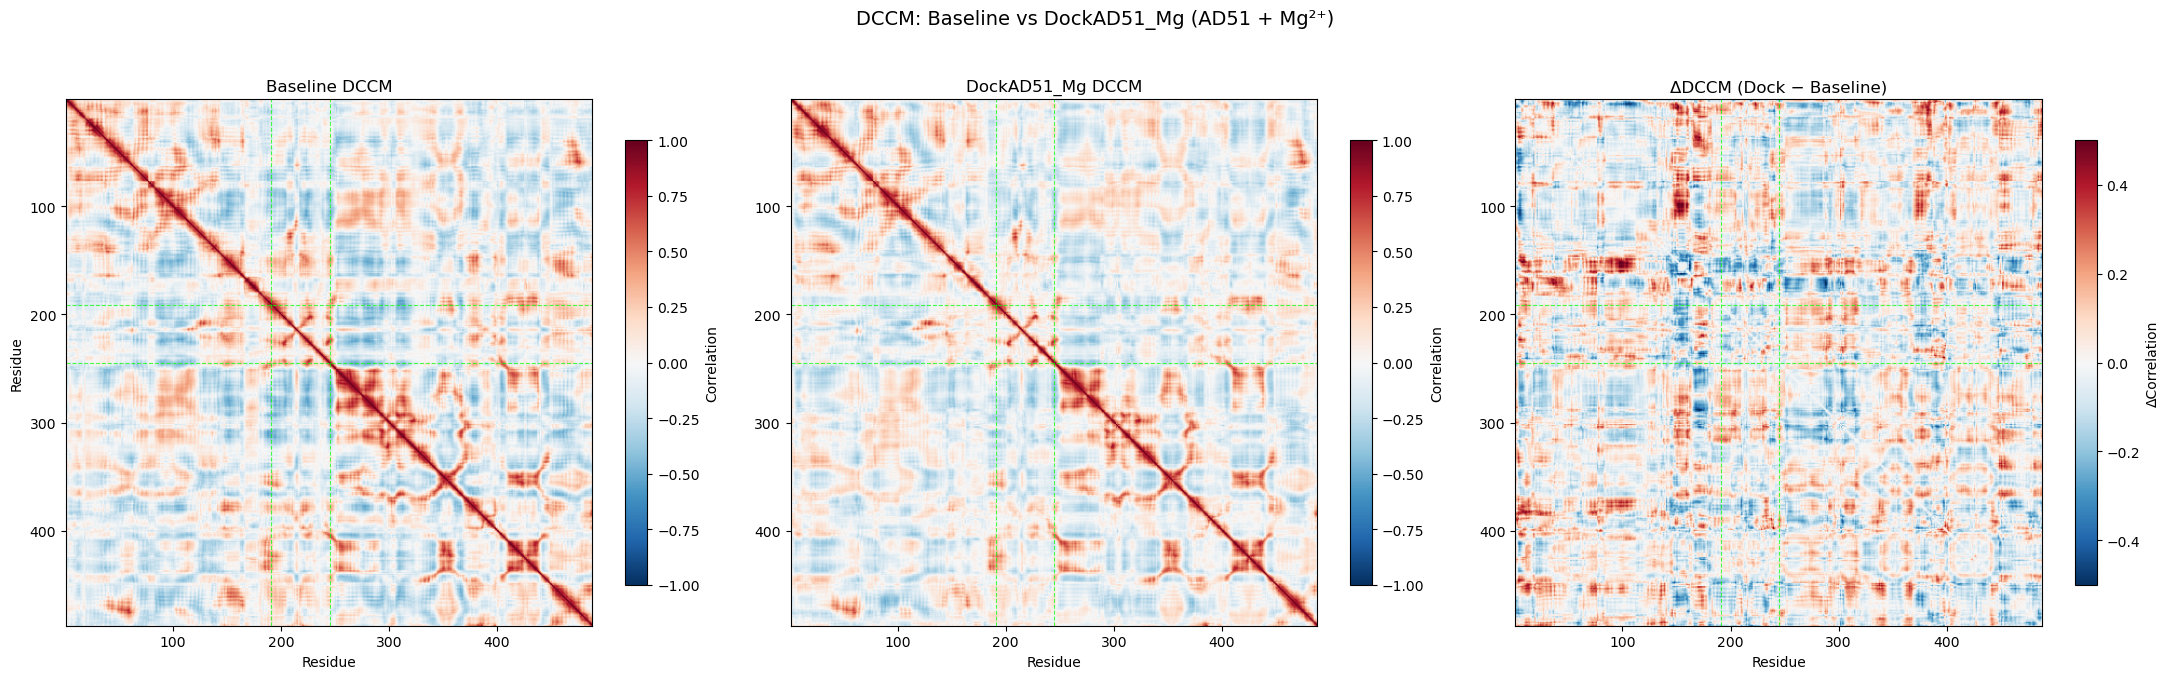

=== ΔDCCM pairs |ΔCorr| > 0.25 (DockAD51_Mg − Baseline) ===

Residue i          Residue j             ΔCorr      Direction
--------------------------------------------------------------
ASN171             LYS288               -0.557    ↓ less corr
THR8               HID151                0.556    ↑ more corr
LEU99              ALA153                0.544    ↑ more corr
LEU99              LYS155                0.535    ↑ more corr
THR170             LYS288               -0.534    ↓ less corr
LEU99              TRP152                0.533    ↑ more corr
ASN172             LYS288               -0.528    ↓ less corr
LYS155             LYS162               -0.527    ↓ less corr
SER104             ALA153                0.522    ↑ more corr
LEU99              GLN156                0.522    ↑ more corr
PRO9               HID151                0.516    ↑ more corr
SER36              ASN171                0.514    ↑ more corr
ARG98              TRP152                0.513    ↑ more corr
VAL97   

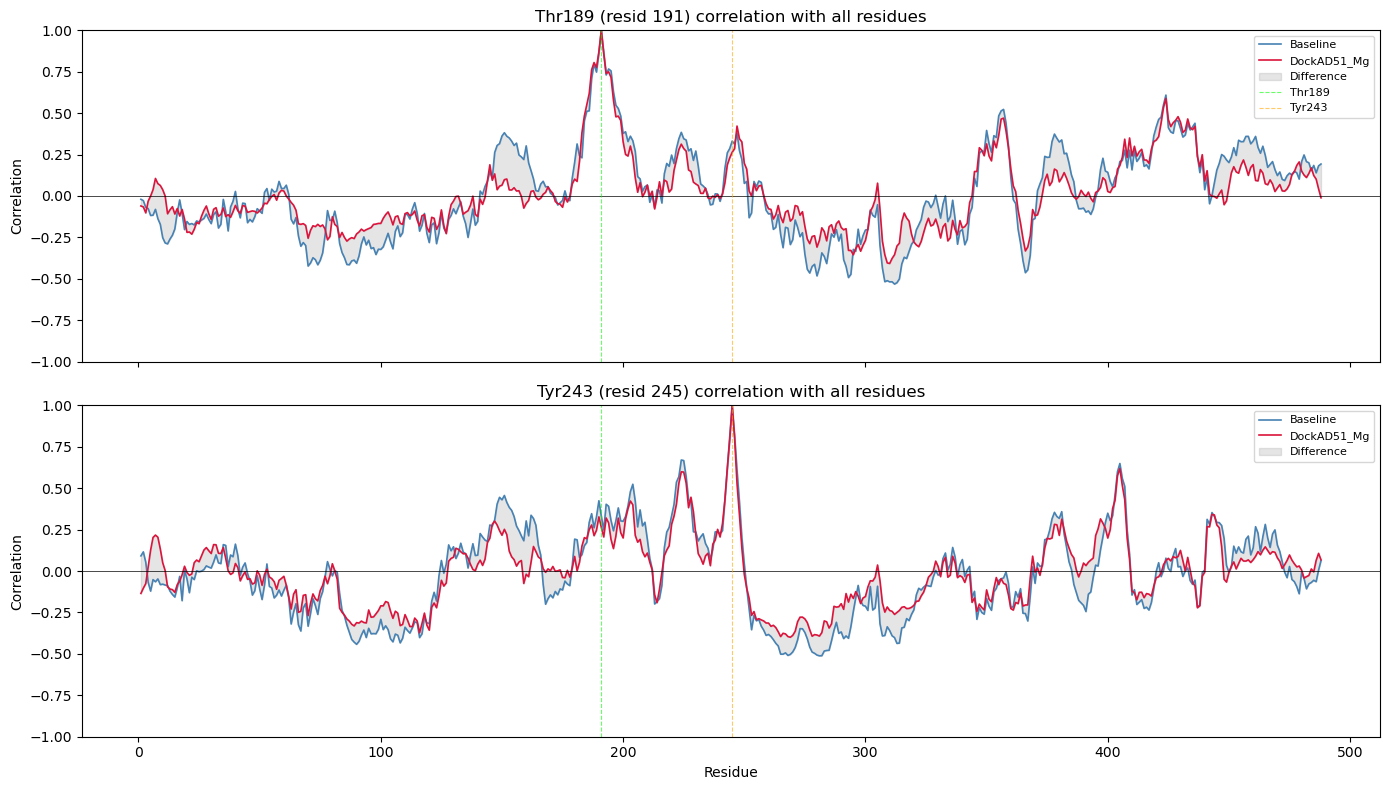

In [ ]:
# ═══════════════════════════════════════════════════════════════
# Cell 1: Setup & Imports
# ═══════════════════════════════════════════════════════════════
import MDAnalysis as mda
from MDAnalysis.analysis import align
from MDAnalysis.analysis.rms import RMSF, RMSD
import numpy as np
import matplotlib.pyplot as plt

# ── Paths ──
ligand_name = "LIG"
base_top = "/home/mk-avid-workstation/MD Sim/3POV/baseline.prmtop"
base_trajs = [f"/home/mk-avid-workstation/MD Sim/Baseline_3POV_{i}/trajectory.dcd" for i in range(1, 4)]

dock_top = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex.prmtop"
dock_trajs = [f"/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_{i}/trajectory.dcd" for i in range(1, 4)]

# ── Selections (protein only — same residue set in both topologies) ──
ca_sel = "protein and name CA"
bb_sel = "protein and backbone"

# ── Allosteric site residues (biological +2 offset) ──
thr189_resid = 191  # Thr189 in topology numbering
tyr243_resid = 245  # Tyr243 in topology numbering


# ═══════════════════════════════════════════════════════════════
# Cell 2: Stable core from baseline
# ═══════════════════════════════════════════════════════════════
def find_stable_core(top, traj, percentile=30):
    u = mda.Universe(top, traj)
    ref = mda.Universe(top, traj)
    ca = u.select_atoms(ca_sel)
    align.AlignTraj(u, ref, select=bb_sel, in_memory=True).run()
    rmsf_vals = RMSF(ca).run().results.rmsf
    threshold = np.percentile(rmsf_vals, percentile)
    stable_resids = ca.resids[rmsf_vals <= threshold]
    core = " or ".join([f"resid {r}" for r in stable_resids])
    print(f"Stable core: {len(stable_resids)} residues (threshold: {threshold:.2f} Å)")
    return f"protein and backbone and ({core})"

shared_core = find_stable_core(base_top, base_trajs[0])


# ═══════════════════════════════════════════════════════════════
# Cell 3: DCCM computation function
# ═══════════════════════════════════════════════════════════════
def compute_dccm(top, trajs, core_sel):
    """Compute replica-averaged DCCM on protein Cα."""
    all_dccm = []
    for traj in trajs:
        u = mda.Universe(top, traj)
        ref = mda.Universe(top, traj)
        align.AlignTraj(u, ref, select=core_sel, in_memory=True).run()

        ca = u.select_atoms(ca_sel)
        n_res = len(ca)

        # Collect positions
        positions = np.zeros((u.trajectory.n_frames, n_res, 3))
        for i, ts in enumerate(u.trajectory):
            positions[i] = ca.positions

        # Fluctuations
        mean_pos = positions.mean(axis=0)
        fluct = positions - mean_pos

        # Covariance via einsum
        cov = np.einsum('fid,fjd->ij', fluct, fluct) / len(u.trajectory)

        # Normalize → correlation
        diag = np.sqrt(np.diag(cov))
        dccm = cov / np.outer(diag, diag)
        all_dccm.append(dccm)

    resids = mda.Universe(top, trajs[0]).select_atoms(ca_sel).resids
    return np.mean(all_dccm, axis=0), resids

print("Computing Baseline DCCM...")
dccm_base, resids_base = compute_dccm(base_top, base_trajs, shared_core)

print("Computing DockAD51_Mg DCCM...")
dccm_dock, resids_dock = compute_dccm(dock_top, dock_trajs, shared_core)

# Verify same residue set
assert np.array_equal(resids_base, resids_dock), "Resid mismatch between topologies!"
resids = resids_base
print(f"DCCM shape: {dccm_base.shape}, residues: {len(resids)}")


# ═══════════════════════════════════════════════════════════════
# Cell 4: Difference map
# ═══════════════════════════════════════════════════════════════
diff = dccm_dock - dccm_base  # positive = more correlated in complex

# Indices for allosteric residues
idx_thr189 = np.where(resids == thr189_resid)[0][0]
idx_tyr243 = np.where(resids == tyr243_resid)[0][0]

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# --- Baseline DCCM ---
im0 = axes[0].imshow(dccm_base, cmap='RdBu_r', vmin=-1, vmax=1,
                       extent=[resids[0], resids[-1], resids[-1], resids[0]])
axes[0].set_title("Baseline DCCM")
axes[0].set_xlabel("Residue")
axes[0].set_ylabel("Residue")
plt.colorbar(im0, ax=axes[0], shrink=0.7, label="Correlation")

# --- DockAD51_Mg DCCM ---
im1 = axes[1].imshow(dccm_dock, cmap='RdBu_r', vmin=-1, vmax=1,
                       extent=[resids[0], resids[-1], resids[-1], resids[0]])
axes[1].set_title("DockAD51_Mg DCCM")
axes[1].set_xlabel("Residue")
plt.colorbar(im1, ax=axes[1], shrink=0.7, label="Correlation")

# --- Difference ---
im2 = axes[2].imshow(diff, cmap='RdBu_r', vmin=-0.5, vmax=0.5,
                       extent=[resids[0], resids[-1], resids[-1], resids[0]])
axes[2].set_title("ΔDCCM (Dock − Baseline)")
axes[2].set_xlabel("Residue")
plt.colorbar(im2, ax=axes[2], shrink=0.7, label="ΔCorrelation")

# Mark Thr189 and Tyr243 on all panels
for ax in axes:
    for r, label in [(thr189_resid, "Thr189"), (tyr243_resid, "Tyr243")]:
        ax.axhline(r, color='lime', lw=0.8, ls='--', alpha=0.7)
        ax.axvline(r, color='lime', lw=0.8, ls='--', alpha=0.7)

plt.suptitle("DCCM: Baseline vs DockAD51_Mg (AD51 + Mg²⁺)", fontsize=14)
plt.tight_layout()
plt.savefig("DCCM_baseline_vs_DockAD51Mg.png", dpi=300, bbox_inches='tight')
plt.show()


# ═══════════════════════════════════════════════════════════════
# Cell 5: Threshold pairs (|ΔCorr| > 0.25)
# ═══════════════════════════════════════════════════════════════
threshold = 0.25

rows, cols = np.where(np.abs(diff) > threshold)
mask = rows < cols  # upper triangle only
rows, cols = rows[mask], cols[mask]
delta_vals = diff[rows, cols]

# Resid → name lookup
u_ref = mda.Universe(base_top, base_trajs[0])
ca_atoms = u_ref.select_atoms(ca_sel)
resid_to_name = {atom.resid: atom.resname for atom in ca_atoms}

# Sort by |ΔCorr|
sort_idx = np.argsort(np.abs(delta_vals))[::-1]
res_i = resids[rows[sort_idx]]
res_j = resids[cols[sort_idx]]
delta_s = delta_vals[sort_idx]

print(f"=== ΔDCCM pairs |ΔCorr| > {threshold} (DockAD51_Mg − Baseline) ===\n")
print(f"{'Residue i':<18} {'Residue j':<18} {'ΔCorr':>8} {'Direction':>14}")
print("-" * 62)

for di, dj, dv in zip(res_i, res_j, delta_s):
    name_i = f"{resid_to_name.get(di, '???')}{di}"
    name_j = f"{resid_to_name.get(dj, '???')}{dj}"
    direction = "↑ more corr" if dv > 0 else "↓ less corr"
    print(f"{name_i:<18} {name_j:<18} {dv:>8.3f} {direction:>14}")

print(f"\nTotal pairs: {len(delta_s)}")

# Unique residues involved
unique_resids = np.unique(np.concatenate([res_i, res_j]))
unique_names = [f"{resid_to_name.get(r, '???')}{r}" for r in unique_resids]
print(f"\n=== Unique residues involved ({len(unique_names)}) ===")
for name in sorted(unique_names, key=lambda x: int(''.join(filter(str.isdigit, x)))):
    print(f"  {name}")

# Check if Thr189/Tyr243 appear
for r, label in [(thr189_resid, "Thr189"), (tyr243_resid, "Tyr243")]:
    if r in unique_resids:
        print(f"\n✓ {label} (resid {r}) appears in ΔDCCM above threshold")
    else:
        print(f"\n✗ {label} (resid {r}) NOT in ΔDCCM above threshold")


# ═══════════════════════════════════════════════════════════════
# Cell 6: Thr189/Tyr243 correlation profiles
# ═══════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

for ax, (idx, r, label) in zip(axes, [(idx_thr189, thr189_resid, "Thr189"),
                                        (idx_tyr243, tyr243_resid, "Tyr243")]):
    ax.plot(resids, dccm_base[idx, :], label="Baseline", color="steelblue", lw=1.2)
    ax.plot(resids, dccm_dock[idx, :], label="DockAD51_Mg", color="crimson", lw=1.2)
    ax.fill_between(resids, dccm_base[idx, :], dccm_dock[idx, :],
                     alpha=0.2, color='grey', label="Difference")
    ax.axhline(0, color='k', lw=0.5)
    ax.axvline(thr189_resid, color='lime', ls='--', lw=0.8, alpha=0.6, label="Thr189" if ax == axes[0] else "")
    ax.axvline(tyr243_resid, color='orange', ls='--', lw=0.8, alpha=0.6, label="Tyr243" if ax == axes[0] else "")
    ax.set_ylabel("Correlation")
    ax.set_title(f"{label} (resid {r}) correlation with all residues")
    ax.legend(loc='upper right', fontsize=8)
    ax.set_ylim(-1, 1)

axes[1].set_xlabel("Residue")
plt.tight_layout()
plt.savefig("Thr189_Tyr243_correlation_profiles.png", dpi=300, bbox_inches='tight')
plt.show()

Crystal DNA atoms: 772
Crystal protein Cα: 445

Replica 1: 38 ligand atoms, 5112 frames, 445 shared Cα
  Min distance range: 1.50 – 6.19 Å

Replica 2: 38 ligand atoms, 5112 frames, 445 shared Cα
  Min distance range: 0.96 – 7.77 Å

Replica 3: 38 ligand atoms, 5112 frames, 445 shared Cα
  Min distance range: 0.16 – 7.16 Å


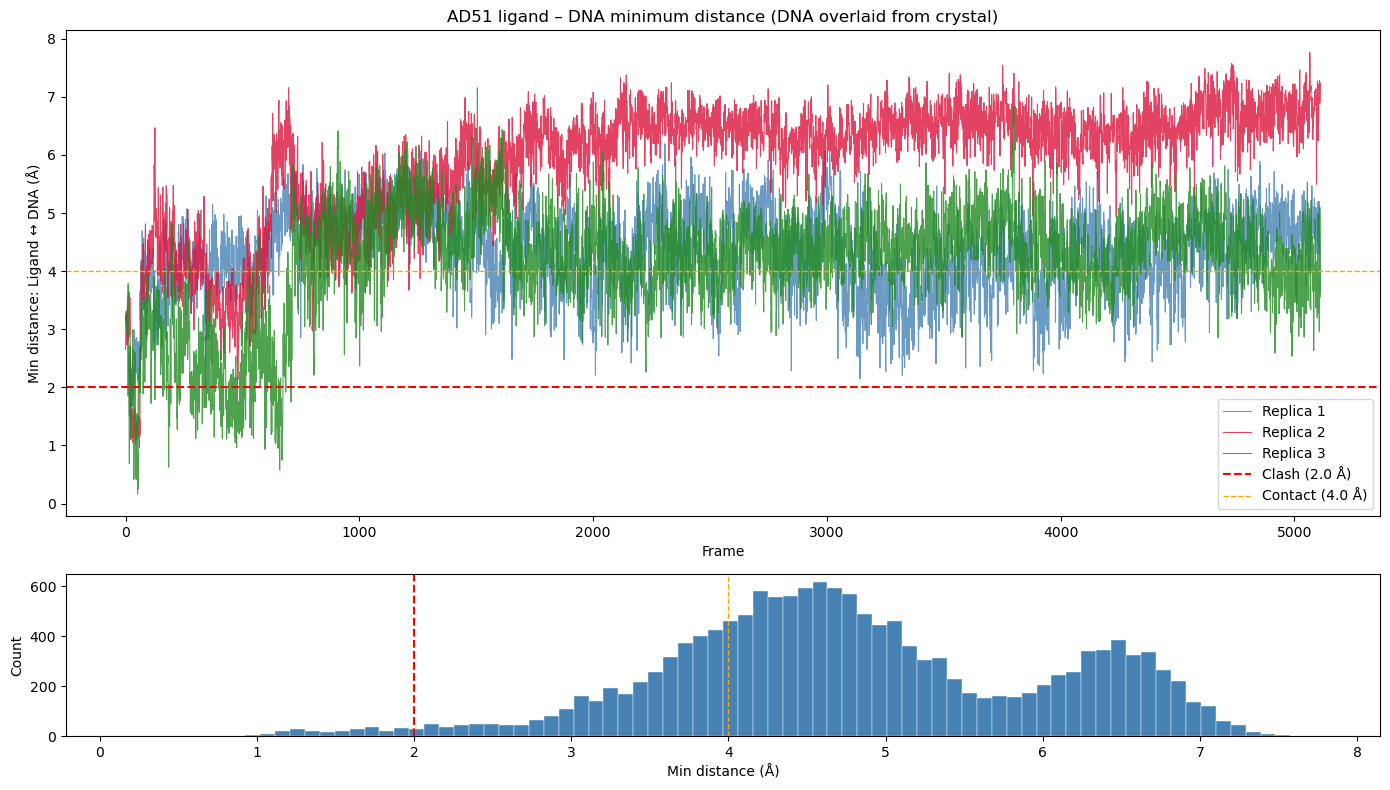


=== Summary (15336 frames) ===
Minimum distance ever:    0.16 Å
Mean minimum distance:    4.79 Å
Frames with clash (<2.0Å): 277 (1.8%)
Frames with contact (<4.0Å): 3727 (24.3%)


In [ ]:
import MDAnalysis as mda
from MDAnalysis.analysis import align
import numpy as np
import matplotlib.pyplot as plt

# ── Paths ──
ligand_name = "LIG"
dock_top = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex.prmtop"
dock_trajs = [
    "/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_1/trajectory.dcd",
    "/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_3/trajectory.dcd",
    "/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_5/trajectory.dcd",
]

crystal_pdb = "/home/mk-avid-workstation/MD Sim/3POV.pdb"  # raw from RCSB

# ── Load crystal structure ──
u_xtal = mda.Universe(crystal_pdb)
dna_xtal = u_xtal.select_atoms("nucleic")
protein_xtal = u_xtal.select_atoms("protein and name CA")

print(f"Crystal DNA atoms: {len(dna_xtal)}")
print(f"Crystal protein Cα: {len(protein_xtal)}")

# ── Thresholds ──
clash_threshold = 2.0
contact_threshold = 4.0

all_min_dists = []

for rep, traj in enumerate(dock_trajs, 1):
    u = mda.Universe(dock_top, traj)
    protein_traj = u.select_atoms("protein and name CA")
    ligand = u.select_atoms(f"resname {ligand_name}")

    # Shared residues between crystal and trajectory
    xtal_resids = set(protein_xtal.resids)
    traj_resids = set(protein_traj.resids)
    shared = sorted(xtal_resids & traj_resids)
    shared_sel = "protein and name CA and (" + " or ".join([f"resid {r}" for r in shared]) + ")"

    protein_xtal_shared = u_xtal.select_atoms(shared_sel)
    protein_traj_shared = u.select_atoms(shared_sel)

    print(f"\nReplica {rep}: {len(ligand)} ligand atoms, {u.trajectory.n_frames} frames, {len(shared)} shared Cα")

    min_dists = []

    for ts in u.trajectory:
        R, rmsd_val = align.rotation_matrix(
            protein_xtal_shared.positions - protein_xtal_shared.center_of_mass(),
            protein_traj_shared.positions - protein_traj_shared.center_of_mass()
        )

        dna_transformed = (dna_xtal.positions - protein_xtal_shared.center_of_mass()) @ R.T + protein_traj_shared.center_of_mass()

        diff = ligand.positions[:, None, :] - dna_transformed[None, :, :]
        dists = np.sqrt((diff ** 2).sum(axis=2))
        min_dists.append(dists.min())

    all_min_dists.append(np.array(min_dists))
    print(f"  Min distance range: {min(min_dists):.2f} – {max(min_dists):.2f} Å")

# ── Plot ──
fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [3, 1]})

ax = axes[0]
colors = ['steelblue', 'crimson', 'forestgreen']
for rep, (dists, color) in enumerate(zip(all_min_dists, colors), 1):
    ax.plot(np.arange(len(dists)), dists, color=color, lw=0.8, alpha=0.8, label=f"Replica {rep}")

ax.axhline(clash_threshold, color='red', ls='--', lw=1.5, label=f"Clash ({clash_threshold} Å)")
ax.axhline(contact_threshold, color='orange', ls='--', lw=1.0, label=f"Contact ({contact_threshold} Å)")
ax.set_ylabel("Min distance: Ligand ↔ DNA (Å)")
ax.set_xlabel("Frame")
ax.set_title("AD51 ligand – DNA minimum distance (DNA overlaid from crystal)")
ax.legend()

ax2 = axes[1]
combined = np.concatenate(all_min_dists)
ax2.hist(combined, bins=80, color='steelblue', edgecolor='white', lw=0.3)
ax2.axvline(clash_threshold, color='red', ls='--', lw=1.5)
ax2.axvline(contact_threshold, color='orange', ls='--', lw=1.0)
ax2.set_xlabel("Min distance (Å)")
ax2.set_ylabel("Count")

plt.tight_layout()
plt.savefig("ligand_DNA_clash_check.png", dpi=300, bbox_inches='tight')
plt.show()

# ── Summary ──
n_clash = (combined < clash_threshold).sum()
n_contact = (combined < contact_threshold).sum()
print(f"\n=== Summary ({len(combined)} frames) ===")
print(f"Minimum distance ever:    {combined.min():.2f} Å")
print(f"Mean minimum distance:    {combined.mean():.2f} Å")
print(f"Frames with clash (<{clash_threshold}Å): {n_clash} ({100*n_clash/len(combined):.1f}%)")
print(f"Frames with contact (<{contact_threshold}Å): {n_contact} ({100*n_contact/len(combined):.1f}%)")

In [ ]:
# ── Check alignment quality ──
u_xtal = mda.Universe(crystal_pdb)
u_traj = mda.Universe(dock_top, dock_trajs[0])

xtal_ca = u_xtal.select_atoms("protein and name CA")
traj_ca = u_traj.select_atoms("protein and name CA")

print("Crystal resids:", xtal_ca.resids[:10], "...", xtal_ca.resids[-10:])
print("Traj resids:   ", traj_ca.resids[:10], "...", traj_ca.resids[-10:])
print(f"Crystal Cα count: {len(xtal_ca)}")
print(f"Traj Cα count:    {len(traj_ca)}")

# Check overlap
xtal_set = set(xtal_ca.resids)
traj_set = set(traj_ca.resids)
shared = xtal_set & traj_set
only_xtal = xtal_set - traj_set
only_traj = traj_set - xtal_set

print(f"\nShared resids: {len(shared)}")
print(f"Only in crystal: {len(only_xtal)} → {sorted(only_xtal)[:20]}")
print(f"Only in traj:    {len(only_traj)} → {sorted(only_traj)[:20]}")

Crystal resids: [ 4  5  6  7  8  9 10 11 12 13] ... [472 473 474 475 476 477 478 479 480 481]
Traj resids:    [ 1  2  3  4  5  6  7  8  9 10] ... [479 480 481 482 483 484 485 486 487 488]
Crystal Cα count: 445
Traj Cα count:    488

Shared resids: 445
Only in crystal: 0 → []
Only in traj:    43 → [1, 2, 3, 156, 157, 158, 159, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177]


In [ ]:
# ── Which DNA atoms are closest? ──
u = mda.Universe(dock_top, dock_trajs[0])
u_xtal = mda.Universe(crystal_pdb)

protein_traj = u.select_atoms("protein and name CA")
ligand = u.select_atoms(f"resname {ligand_name}")
dna_xtal = u_xtal.select_atoms("nucleic")

xtal_resids = set(u_xtal.select_atoms("protein and name CA").resids)
traj_resids = set(protein_traj.resids)
shared = sorted(xtal_resids & traj_resids)
shared_sel = "protein and name CA and (" + " or ".join([f"resid {r}" for r in shared]) + ")"

protein_xtal_shared = u_xtal.select_atoms(shared_sel)
protein_traj_shared = u.select_atoms(shared_sel)

# Check frame 0
u.trajectory[0]
R, _ = align.rotation_matrix(
    protein_xtal_shared.positions - protein_xtal_shared.center_of_mass(),
    protein_traj_shared.positions - protein_traj_shared.center_of_mass()
)
dna_transformed = (dna_xtal.positions - protein_xtal_shared.center_of_mass()) @ R.T + protein_traj_shared.center_of_mass()

diff = ligand.positions[:, None, :] - dna_transformed[None, :, :]
dists = np.sqrt((diff ** 2).sum(axis=2))

# For each DNA atom, find min distance to any ligand atom
dna_min_dists = dists.min(axis=0)

# Top 20 closest DNA atoms
closest_idx = np.argsort(dna_min_dists)[:20]
print("Closest DNA atoms to ligand:")
print(f"{'Atom name':<10} {'Resname':<8} {'Resid':<8} {'Dist (Å)':>10}")
print("-" * 40)
for i in closest_idx:
    atom = dna_xtal[i]
    print(f"{atom.name:<10} {atom.resname:<8} {atom.resid:<8} {dna_min_dists[i]:>10.2f}")

Closest DNA atoms to ligand:
Atom name  Resname  Resid      Dist (Å)
----------------------------------------
O5'        DG       2              3.23
C3'        DG       2              3.39
OP1        DG       3              3.53
OP2        DG       3              3.61
C5'        DG       2              3.70
P          DG       3              3.85
O3'        DG       2              3.96
C4'        DG       2              4.24
C2'        DG       2              4.30
O5'        DG       3              5.45
O4'        DG       2              5.45
C1'        DG       2              5.57
C8         DG       2              6.34
C5'        DG       3              6.34
N9         DG       2              6.66
C8         DG       3              7.22
N7         DG       2              7.42
N7         DG       3              7.63
C4'        DG       3              7.67
O4'        DG       3              7.79


In [ ]:
# ── Export one frame for PyMOL visualization ──
# Write ligand + protein from frame 0
u.trajectory[0]
u.atoms.write("/home/mk-avid-workstation/MD Sim/3POV/frame0_complex.pdb")

# Write transformed DNA
dna_xtal_copy = dna_xtal.copy()
dna_xtal_copy.positions = dna_transformed
dna_xtal_copy.write("/home/mk-avid-workstation/MD Sim/3POV/dna_overlay_frame0.pdb")

print("Saved. Load both in PyMOL and color DNA/ligand differently.")

/home/mk-avid-workstation/miniforge3/envs/MD_science/lib/python3.10/site-packages/MDAnalysis/coordinates/PDB.py:1154: UserWarning: Found no information for attr: 'altLocs' Using default value of ' '
  warnings.warn("Found no information for attr: '{}'"
/home/mk-avid-workstation/miniforge3/envs/MD_science/lib/python3.10/site-packages/MDAnalysis/coordinates/PDB.py:1154: UserWarning: Found no information for attr: 'icodes' Using default value of ' '
  warnings.warn("Found no information for attr: '{}'"
/home/mk-avid-workstation/miniforge3/envs/MD_science/lib/python3.10/site-packages/MDAnalysis/coordinates/PDB.py:1154: UserWarning: Found no information for attr: 'chainIDs' Using default value of ''
  warnings.warn("Found no information for attr: '{}'"
/home/mk-avid-workstation/miniforge3/envs/MD_science/lib/python3.10/site-packages/MDAnalysis/coordinates/PDB.py:1154: UserWarning: Found no information for attr: 'occupancies' Using default value of '1.0'
  warnings.warn("Found no information

Saved. Load both in PyMOL and color DNA/ligand differently.


In [ ]:
# ── Export multiple frames for PyMOL ──
u = mda.Universe(dock_top, dock_trajs[0])
u_xtal = mda.Universe(crystal_pdb)

dna_xtal = u_xtal.select_atoms("nucleic")
protein_xtal_shared = u_xtal.select_atoms(shared_sel)
protein_traj_shared = u.select_atoms(shared_sel)
ligand = u.select_atoms(f"resname {ligand_name}")

n_frames = u.trajectory.n_frames
frames_to_export = {
    "start": 0,
    "mid": n_frames // 2,
    "end": n_frames - 1,
    "worst": int(np.argmin(all_min_dists[0]))  # closest clash frame from replica 1
}

out_dir = "/home/mk-avid-workstation/MD Sim/3POV"

for label, frame_idx in frames_to_export.items():
    u.trajectory[frame_idx]

    # Transform DNA
    R, _ = align.rotation_matrix(
        protein_xtal_shared.positions - protein_xtal_shared.center_of_mass(),
        protein_traj_shared.positions - protein_traj_shared.center_of_mass()
    )
    dna_transformed = (dna_xtal.positions - protein_xtal_shared.center_of_mass()) @ R.T + protein_traj_shared.center_of_mass()

    # Min distance for this frame
    diff = ligand.positions[:, None, :] - dna_transformed[None, :, :]
    dists = np.sqrt((diff ** 2).sum(axis=2))
    min_d = dists.min()

    # Save complex
    u.atoms.write(f"{out_dir}/frame_{label}.pdb")

    # Save transformed DNA
    dna_copy = dna_xtal.copy()
    dna_copy.positions = dna_transformed
    dna_copy.write(f"{out_dir}/dna_{label}.pdb")

    print(f"Frame {label} (idx {frame_idx}): min distance = {min_d:.2f} Å")

Frame start (idx 0): min distance = 3.23 Å
Frame mid (idx 2556): min distance = 50.12 Å
Frame end (idx 5111): min distance = 123.35 Å
Frame worst (idx 16): min distance = 176.82 Å


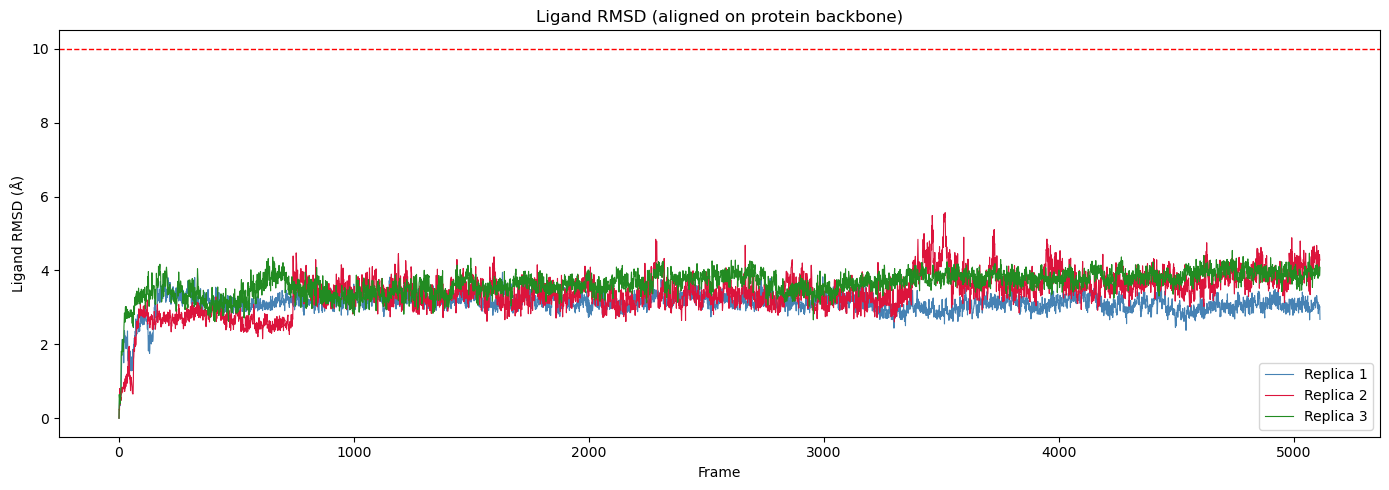

Replica 1: final ligand RMSD = 2.7 Å
Replica 2: final ligand RMSD = 4.3 Å
Replica 3: final ligand RMSD = 4.1 Å


In [ ]:
# ── Ligand RMSD to check dissociation ──
fig, ax = plt.subplots(figsize=(14, 5))
colors = ['steelblue', 'crimson', 'forestgreen']

for rep, (traj, color) in enumerate(zip(dock_trajs, colors), 1):
    u = mda.Universe(dock_top, traj)
    ref = mda.Universe(dock_top, traj)

    # Align on protein backbone
    align.AlignTraj(u, ref, select="protein and backbone", in_memory=True).run()

    lig = u.select_atoms(f"resname {ligand_name}")
    lig_ref = ref.select_atoms(f"resname {ligand_name}")
    ref_pos = lig_ref.positions.copy()

    rmsds = []
    for ts in u.trajectory:
        diff = lig.positions - ref_pos
        rmsd = np.sqrt((diff ** 2).sum(axis=1).mean())
        rmsds.append(rmsd)

    ax.plot(rmsds, color=color, lw=0.8, label=f"Replica {rep}")

ax.set_xlabel("Frame")
ax.set_ylabel("Ligand RMSD (Å)")
ax.set_title("Ligand RMSD (aligned on protein backbone)")
ax.legend()
ax.axhline(10, color='red', ls='--', lw=1, label="Dissociation threshold")
plt.tight_layout()
plt.savefig("ligand_rmsd_dissociation_check.png", dpi=300, bbox_inches='tight')
plt.show()

# Quick summary
for rep, (traj, color) in enumerate(zip(dock_trajs, colors), 1):
    u = mda.Universe(dock_top, traj)
    ref = mda.Universe(dock_top, traj)
    align.AlignTraj(u, ref, select="protein and backbone", in_memory=True).run()
    lig = u.select_atoms(f"resname {ligand_name}")
    lig_ref = ref.select_atoms(f"resname {ligand_name}")
    ref_pos = lig_ref.positions.copy()

    u.trajectory[-1]
    final_rmsd = np.sqrt(((lig.positions - ref_pos) ** 2).sum(axis=1).mean())
    print(f"Replica {rep}: final ligand RMSD = {final_rmsd:.1f} Å")

Replica 1: 5112 frames
  Frame 0/5112, min dist: 3.23 Å
  Frame 1000/5112, min dist: 4.98 Å
  Frame 2000/5112, min dist: 2.76 Å
  Frame 3000/5112, min dist: 5.30 Å
  Frame 4000/5112, min dist: 3.77 Å
  Frame 5000/5112, min dist: 4.27 Å
  Range: 1.50 – 6.19 Å
Replica 2: 5112 frames
  Frame 0/5112, min dist: 3.27 Å
  Frame 1000/5112, min dist: 2.21 Å
  Frame 2000/5112, min dist: 0.70 Å
  Frame 3000/5112, min dist: 2.25 Å
  Frame 4000/5112, min dist: 2.65 Å
  Frame 5000/5112, min dist: 2.46 Å
  Range: 0.11 – 4.97 Å
Replica 3: 5112 frames
  Frame 0/5112, min dist: 2.65 Å
  Frame 1000/5112, min dist: 4.54 Å
  Frame 2000/5112, min dist: 7.08 Å
  Frame 3000/5112, min dist: 6.34 Å
  Frame 4000/5112, min dist: 6.87 Å
  Frame 5000/5112, min dist: 7.06 Å
  Range: 0.96 – 7.77 Å


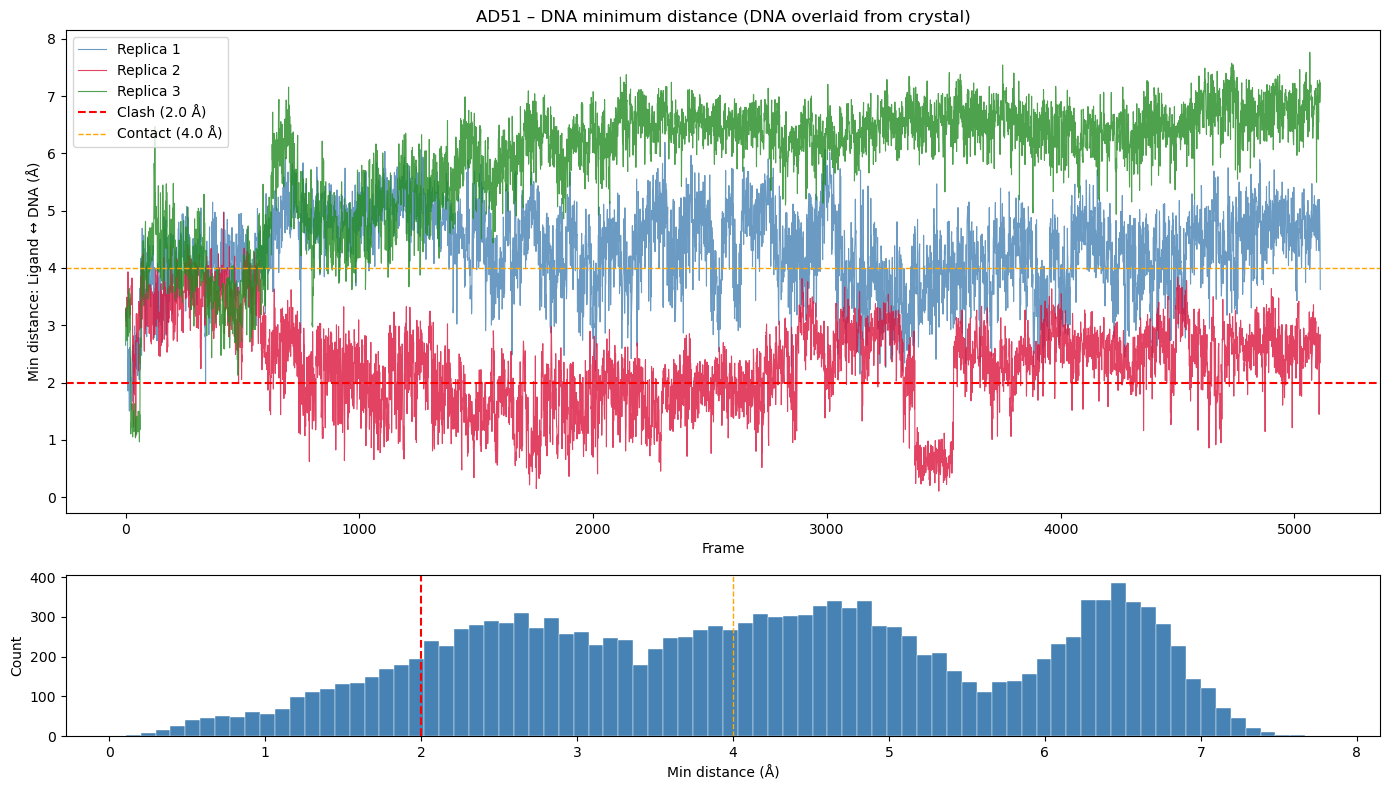


=== Summary (15336 frames) ===
Min distance ever:  0.11 Å
Mean min distance:  4.18 Å
Clash (<2.0Å):   1666 (10.9%)
Contact (<4.0Å): 7032 (45.9%)


In [ ]:
import MDAnalysis as mda
from MDAnalysis.analysis import align
import numpy as np
import matplotlib.pyplot as plt

# ── Paths ──
ligand_name = "LIG"
dock_top = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex.prmtop"
dock_trajs = [f"/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_{i}/trajectory.dcd" for i in range(1, 4)]
crystal_pdb = "/home/mk-avid-workstation/MD Sim/3POV.pdb"

# ── Load crystal ──
u_xtal = mda.Universe(crystal_pdb)
dna_xtal = u_xtal.select_atoms("nucleic")
dna_pos = dna_xtal.positions.copy()

xtal_resids = set(u_xtal.select_atoms("protein and name CA").resids)

# ── Precompute crystal reference ──
protein_xtal_shared = u_xtal.select_atoms("protein and name CA")
xtal_com = protein_xtal_shared.center_of_mass()
xtal_centered = protein_xtal_shared.positions - xtal_com
dna_centered = dna_pos - xtal_com

clash_threshold = 2.0
contact_threshold = 4.0
all_min_dists = []

for rep, traj in enumerate(dock_trajs, 1):
    u = mda.Universe(dock_top, traj)

    # Align entire trajectory on protein backbone first (in memory)
    ref = mda.Universe(dock_top, traj)
    align.AlignTraj(u, ref, select="protein and backbone", in_memory=True).run()

    traj_resids = set(u.select_atoms("protein and name CA").resids)
    shared = sorted(xtal_resids & traj_resids)
    shared_sel = "protein and name CA and (" + " or ".join([f"resid {r}" for r in shared]) + ")"

    protein_traj_shared = u.select_atoms(shared_sel)
    ligand = u.select_atoms(f"resname {ligand_name}")

    print(f"Replica {rep}: {u.trajectory.n_frames} frames")

    min_dists = np.zeros(u.trajectory.n_frames)

    for i, ts in enumerate(u.trajectory):
        traj_com = protein_traj_shared.center_of_mass()
        traj_centered = protein_traj_shared.positions - traj_com

        R, _ = align.rotation_matrix(xtal_centered, traj_centered)
        dna_transformed = dna_centered @ R.T + traj_com

        # Use scipy for fast distance
        from scipy.spatial.distance import cdist
        dists = cdist(ligand.positions, dna_transformed)
        min_dists[i] = dists.min()

        if i % 1000 == 0:
            print(f"  Frame {i}/{u.trajectory.n_frames}, min dist: {min_dists[i]:.2f} Å")

    all_min_dists.append(min_dists)
    print(f"  Range: {min_dists.min():.2f} – {min_dists.max():.2f} Å")

# ── Plot ──
fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [3, 1]})

ax = axes[0]
colors = ['steelblue', 'crimson', 'forestgreen']
for rep, (dists, color) in enumerate(zip(all_min_dists, colors), 1):
    ax.plot(dists, color=color, lw=0.8, alpha=0.8, label=f"Replica {rep}")

ax.axhline(clash_threshold, color='red', ls='--', lw=1.5, label=f"Clash ({clash_threshold} Å)")
ax.axhline(contact_threshold, color='orange', ls='--', lw=1.0, label=f"Contact ({contact_threshold} Å)")
ax.set_ylabel("Min distance: Ligand ↔ DNA (Å)")
ax.set_xlabel("Frame")
ax.set_title("AD51 – DNA minimum distance (DNA overlaid from crystal)")
ax.legend()

ax2 = axes[1]
combined = np.concatenate(all_min_dists)
ax2.hist(combined, bins=80, color='steelblue', edgecolor='white', lw=0.3)
ax2.axvline(clash_threshold, color='red', ls='--', lw=1.5)
ax2.axvline(contact_threshold, color='orange', ls='--', lw=1.0)
ax2.set_xlabel("Min distance (Å)")
ax2.set_ylabel("Count")

plt.tight_layout()
plt.savefig("ligand_DNA_clash_check.png", dpi=300, bbox_inches='tight')
plt.show()

# ── Summary ──
combined = np.concatenate(all_min_dists)
n_clash = (combined < clash_threshold).sum()
n_contact = (combined < contact_threshold).sum()
print(f"\n=== Summary ({len(combined)} frames) ===")
print(f"Min distance ever:  {combined.min():.2f} Å")
print(f"Mean min distance:  {combined.mean():.2f} Å")
print(f"Clash (<{clash_threshold}Å):   {n_clash} ({100*n_clash/len(combined):.1f}%)")
print(f"Contact (<{contact_threshold}Å): {n_contact} ({100*n_contact/len(combined):.1f}%)")

In [ ]:
# ── Verify alignment is correct ──
u_xtal = mda.Universe(crystal_pdb)
u_traj = mda.Universe(dock_top, dock_trajs[0])

xtal_ca = u_xtal.select_atoms("protein and name CA")
traj_ca = u_traj.select_atoms("protein and name CA")

# Compare first 10 shared resids — do the resnames match?
xtal_resids = set(xtal_ca.resids)
traj_resids = set(traj_ca.resids)
shared = sorted(xtal_resids & traj_resids)

print(f"{'Resid':<8} {'Crystal':>10} {'Trajectory':>12} {'Match':>8}")
print("-" * 42)
for r in shared[:20]:
    xname = xtal_ca.select_atoms(f"resid {r}")[0].resname
    tname = traj_ca.select_atoms(f"resid {r}")[0].resname
    match = "✓" if xname == tname else "✗ MISMATCH"
    print(f"{r:<8} {xname:>10} {tname:>12} {match:>8}")

# Also check the last 10
print("...")
for r in shared[-10:]:
    xname = xtal_ca.select_atoms(f"resid {r}")[0].resname
    tname = traj_ca.select_atoms(f"resid {r}")[0].resname
    match = "✓" if xname == tname else "✗ MISMATCH"
    print(f"{r:<8} {xname:>10} {tname:>12} {match:>8}")

Resid       Crystal   Trajectory    Match
------------------------------------------
4               THR          GLU ✗ MISMATCH
5               PRO          ALA ✗ MISMATCH
6               THR          THR        ✓
7               PRO          PRO        ✓
8               ALA          THR ✗ MISMATCH
9               ASP          PRO ✗ MISMATCH
10              LEU          ALA ✗ MISMATCH
11              PHE          ASP ✗ MISMATCH
12              SER          LEU ✗ MISMATCH
13              GLU          PHE ✗ MISMATCH
14              ASP          SER ✗ MISMATCH
15              TYR          GLU ✗ MISMATCH
16              LEU          ASP ✗ MISMATCH
17              VAL          TYR ✗ MISMATCH
18              ASP          LEU ✗ MISMATCH
19              THR          VAL ✗ MISMATCH
20              LEU          ASP ✗ MISMATCH
21              ASP          THR ✗ MISMATCH
22              GLY          LEU ✗ MISMATCH
23              LEU          ASP ✗ MISMATCH
...
472             LYS          TYR ✗ 

In [ ]:
# ── Sequence-based alignment instead of resid matching ──
u_xtal = mda.Universe(crystal_pdb)
u_traj = mda.Universe(dock_top, dock_trajs[0])

xtal_ca = u_xtal.select_atoms("protein and name CA")
traj_ca = u_traj.select_atoms("protein and name CA")

# Crystal resid N = Trajectory resid N+2
# So align crystal resid R with trajectory resid R+2
offset = 2

xtal_resids = xtal_ca.resids
matched_xtal = []
matched_traj = []

for r in xtal_resids:
    traj_r = r + offset
    xtal_atom = xtal_ca.select_atoms(f"resid {r}")
    traj_atom = traj_ca.select_atoms(f"resid {traj_r}")
    if len(xtal_atom) == 1 and len(traj_atom) == 1:
        if xtal_atom[0].resname == traj_atom[0].resname:
            matched_xtal.append(r)
            matched_traj.append(traj_r)

print(f"Matched residues: {len(matched_xtal)}")
print(f"First 10: crystal {matched_xtal[:10]} → traj {matched_traj[:10]}")

# Verify
print(f"\n{'Xtal resid':<12} {'Traj resid':<12} {'Resname':>10}")
print("-" * 36)
for xr, tr in zip(matched_xtal[:10], matched_traj[:10]):
    name = xtal_ca.select_atoms(f"resid {xr}")[0].resname
    print(f"{xr:<12} {tr:<12} {name:>10}")

Matched residues: 433
First 10: crystal [4, 5, 6, 7, 8, 9, 10, 11, 12, 13] → traj [6, 7, 8, 9, 10, 11, 12, 13, 14, 15]

Xtal resid   Traj resid      Resname
------------------------------------
4            6                   THR
5            7                   PRO
6            8                   THR
7            9                   PRO
8            10                  ALA
9            11                  ASP
10           12                  LEU
11           13                  PHE
12           14                  SER
13           15                  GLU


Crystal matched Cα: 433
DNA atoms: 772

Replica 1: 5112 frames, 433 matched Cα
  Frame 0: min dist = 2.98 Å
  Frame 1000: min dist = 4.67 Å
  Frame 2000: min dist = 2.55 Å
  Frame 3000: min dist = 5.04 Å
  Frame 4000: min dist = 3.51 Å
  Frame 5000: min dist = 4.10 Å
  Range: 1.22 – 5.95 Å

Replica 2: 5112 frames, 433 matched Cα
  Frame 0: min dist = 3.02 Å
  Frame 1000: min dist = 1.94 Å
  Frame 2000: min dist = 0.95 Å
  Frame 3000: min dist = 2.00 Å
  Frame 4000: min dist = 2.32 Å
  Frame 5000: min dist = 2.19 Å
  Range: 0.05 – 4.73 Å

Replica 3: 5112 frames, 433 matched Cα
  Frame 0: min dist = 2.40 Å
  Frame 1000: min dist = 4.26 Å
  Frame 2000: min dist = 6.82 Å
  Frame 3000: min dist = 6.04 Å
  Frame 4000: min dist = 6.57 Å
  Frame 5000: min dist = 6.75 Å
  Range: 0.72 – 7.47 Å


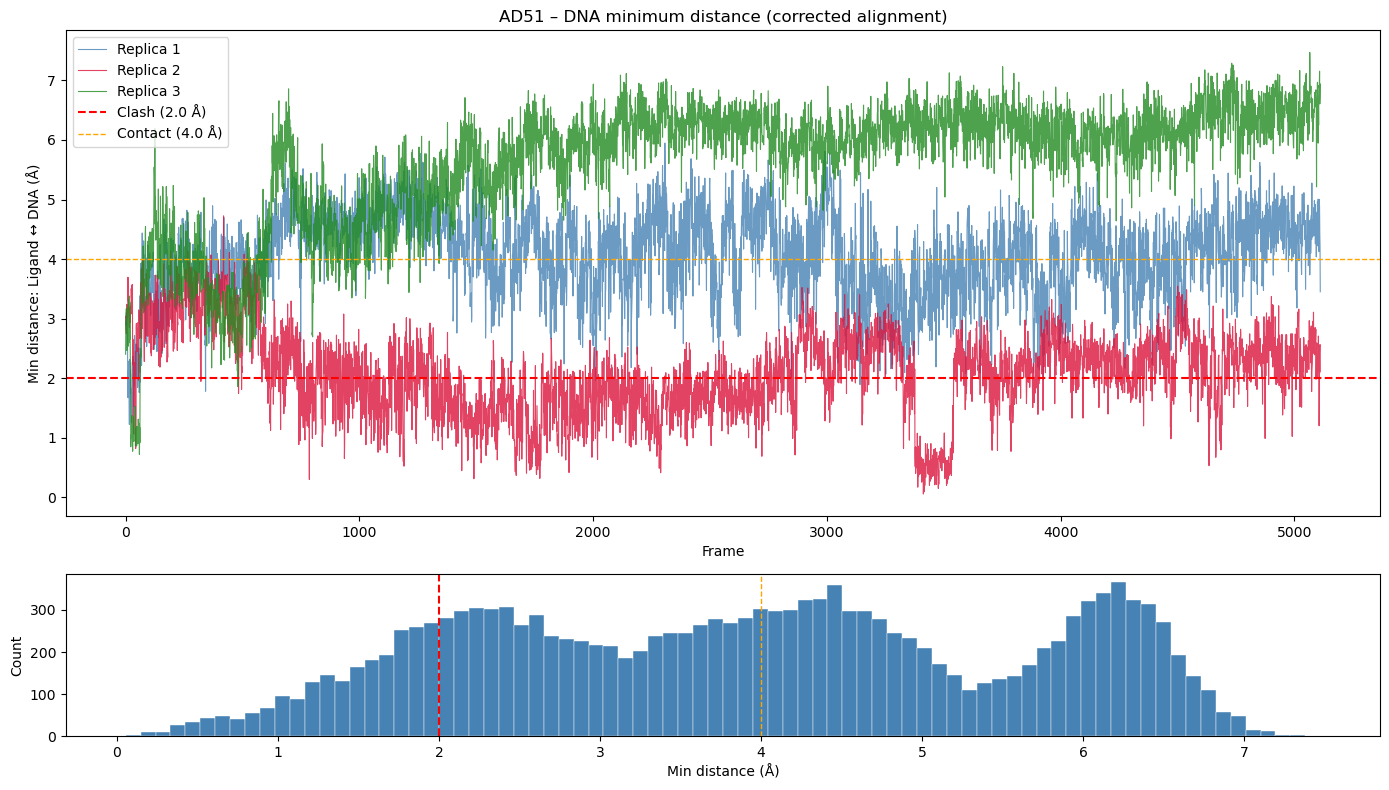


=== Summary (15336 frames) ===
Min distance ever:  0.05 Å
Mean min distance:  3.93 Å
Clash (<2.0Å):   2239 (14.6%)
Contact (<4.0Å): 7802 (50.9%)


In [ ]:
# ── Build matched selections ──
xtal_sel = "protein and name CA and (" + " or ".join([f"resid {r}" for r in matched_xtal]) + ")"
traj_sel = "protein and name CA and (" + " or ".join([f"resid {r}" for r in matched_traj]) + ")"

u_xtal = mda.Universe(crystal_pdb)
dna_xtal = u_xtal.select_atoms("nucleic")
protein_xtal_matched = u_xtal.select_atoms(xtal_sel)
xtal_com = protein_xtal_matched.center_of_mass()
xtal_centered = protein_xtal_matched.positions - xtal_com
dna_centered = dna_xtal.positions - xtal_com

print(f"Crystal matched Cα: {len(protein_xtal_matched)}")
print(f"DNA atoms: {len(dna_xtal)}")

from scipy.spatial.distance import cdist

clash_threshold = 2.0
contact_threshold = 4.0
all_min_dists = []

for rep, traj in enumerate(dock_trajs, 1):
    u = mda.Universe(dock_top, traj)
    ref = mda.Universe(dock_top, traj)
    align.AlignTraj(u, ref, select="protein and backbone", in_memory=True).run()

    protein_traj_matched = u.select_atoms(traj_sel)
    ligand = u.select_atoms(f"resname {ligand_name}")

    print(f"\nReplica {rep}: {u.trajectory.n_frames} frames, {len(protein_traj_matched)} matched Cα")

    min_dists = np.zeros(u.trajectory.n_frames)

    for i, ts in enumerate(u.trajectory):
        traj_com = protein_traj_matched.center_of_mass()
        traj_centered = protein_traj_matched.positions - traj_com

        R, _ = align.rotation_matrix(xtal_centered, traj_centered)
        dna_transformed = dna_centered @ R.T + traj_com

        dists = cdist(ligand.positions, dna_transformed)
        min_dists[i] = dists.min()

        if i % 1000 == 0:
            print(f"  Frame {i}: min dist = {min_dists[i]:.2f} Å")

    all_min_dists.append(min_dists)
    print(f"  Range: {min_dists.min():.2f} – {min_dists.max():.2f} Å")

# ── Plot ──
fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [3, 1]})

ax = axes[0]
colors = ['steelblue', 'crimson', 'forestgreen']
for rep, (dists, color) in enumerate(zip(all_min_dists, colors), 1):
    ax.plot(dists, color=color, lw=0.8, alpha=0.8, label=f"Replica {rep}")
ax.axhline(clash_threshold, color='red', ls='--', lw=1.5, label=f"Clash ({clash_threshold} Å)")
ax.axhline(contact_threshold, color='orange', ls='--', lw=1.0, label=f"Contact ({contact_threshold} Å)")
ax.set_ylabel("Min distance: Ligand ↔ DNA (Å)")
ax.set_xlabel("Frame")
ax.set_title("AD51 – DNA minimum distance (corrected alignment)")
ax.legend()

ax2 = axes[1]
combined = np.concatenate(all_min_dists)
ax2.hist(combined, bins=80, color='steelblue', edgecolor='white', lw=0.3)
ax2.axvline(clash_threshold, color='red', ls='--', lw=1.5)
ax2.axvline(contact_threshold, color='orange', ls='--', lw=1.0)
ax2.set_xlabel("Min distance (Å)")
ax2.set_ylabel("Count")

plt.tight_layout()
plt.savefig("ligand_DNA_clash_check_corrected.png", dpi=300, bbox_inches='tight')
plt.show()

combined = np.concatenate(all_min_dists)
n_clash = (combined < clash_threshold).sum()
n_contact = (combined < contact_threshold).sum()
print(f"\n=== Summary ({len(combined)} frames) ===")
print(f"Min distance ever:  {combined.min():.2f} Å")
print(f"Mean min distance:  {combined.mean():.2f} Å")
print(f"Clash (<{clash_threshold}Å):   {n_clash} ({100*n_clash/len(combined):.1f}%)")
print(f"Contact (<{contact_threshold}Å): {n_contact} ({100*n_contact/len(combined):.1f}%)")

In [ ]:
u_xtal = mda.Universe(crystal_pdb)

# What chains/segments exist?
print("All segments:", u_xtal.segments.segids)

# Check if "protein" selection accidentally grabs non-protein
prot = u_xtal.select_atoms("protein")
nuc = u_xtal.select_atoms("nucleic")
print(f"Protein atoms: {len(prot)}")
print(f"Nucleic atoms: {len(nuc)}")
print(f"Total atoms: {len(u_xtal.atoms)}")
print(f"Protein + Nucleic: {len(prot) + len(nuc)}")

# Check DNA resids
dna = u_xtal.select_atoms("nucleic")
print(f"\nDNA resids: {dna.resids}")
print(f"DNA resnames: {dna.residues.resnames}")
print(f"DNA segids: {dna.segids[:10]}")

# Check if any DNA resids overlap with protein resids used in alignment
print(f"\nDNA resids overlapping with matched_xtal: {set(dna.resids) & set(matched_xtal)}")

All segments: ['A' 'C' 'D' 'A' 'C' 'D']
Protein atoms: 3471
Nucleic atoms: 772
Total atoms: 4373
Protein + Nucleic: 4243

DNA resids: [ 2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  3  3  3  3  3
  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  4  4  4  4  4  4  4
  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  5  5  5  5  5  5  5  5  5
  5  5  5  5  5  5  5  5  5  5  5  5  6  6  6  6  6  6  6  6  6  6  6  6
  6  6  6  6  6  6  6  6  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7
  7  7  7  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  9  9
  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9 10 10 10 10 10 10
 10 10 10 10 10 10 10 10 10 10 10 10 10 11 11 11 11 11 11 11 11 11 11 11
 11 11 11 11 11 11 11 11 12 12 12 12 12 12 12 12 12 12 12 12 12 12 12 12
 12 12 12 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13 13
 14 14 14 14 14 14 14 14 14 14 14 14 14 14 14 14 14 14 14 14 14 14 15 15
 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 15 16 16 16

In [ ]:
# Find the worst frame
u = mda.Universe(dock_top, dock_trajs[0])
ref = mda.Universe(dock_top, dock_trajs[0])
align.AlignTraj(u, ref, select="protein and backbone", in_memory=True).run()

ligand = u.select_atoms(f"resname {ligand_name}")
protein_traj_matched = u.select_atoms(traj_sel)

worst_frame = np.argmin(all_min_dists[0])
u.trajectory[worst_frame]

traj_com = protein_traj_matched.center_of_mass()
traj_centered = protein_traj_matched.positions - traj_com
R, _ = align.rotation_matrix(xtal_centered, traj_centered)
dna_transformed = dna_centered @ R.T + traj_com

dists = cdist(ligand.positions, dna_transformed)
lig_idx, dna_idx = np.unravel_index(dists.argmin(), dists.shape)

lig_atom = ligand[lig_idx]
dna_atom = dna_xtal[dna_idx]

print(f"Worst frame: {worst_frame}")
print(f"Distance: {dists.min():.3f} Å")
print(f"Ligand atom: {lig_atom.name} (index {lig_atom.index})")
print(f"Ligand position: {ligand[lig_idx].position}")
print(f"DNA atom: {dna_atom.name} {dna_atom.resname} {dna_atom.resid}")
print(f"DNA transformed position: {dna_transformed[dna_idx]}")

Worst frame: 16
Distance: 1.223 Å
Ligand atom: H (index 7758)
Ligand position: [47.582603 56.279118 34.078644]
DNA atom: O5' DG 2
DNA transformed position: [48.54262303 57.00127292 34.31054716]


In [ ]:
# ── Check alignment RMSD per frame ──
u = mda.Universe(dock_top, dock_trajs[0])
ref = mda.Universe(dock_top, dock_trajs[0])
align.AlignTraj(u, ref, select="protein and backbone", in_memory=True).run()

protein_traj_matched = u.select_atoms(traj_sel)

# Frame 0 — check alignment RMSD
u.trajectory[0]
traj_com = protein_traj_matched.center_of_mass()
traj_centered = protein_traj_matched.positions - traj_com
R, align_rmsd = align.rotation_matrix(xtal_centered, traj_centered)
print(f"Frame 0 alignment RMSD: {align_rmsd:.2f} Å")

# Also check: where does the transformed DNA land relative to the protein?
dna_transformed = dna_centered @ R.T + traj_com

# Distance from DNA center of mass to protein center of mass
prot_com = u.select_atoms("protein").center_of_mass()
dna_com = dna_transformed.mean(axis=0)
print(f"Protein COM: {prot_com}")
print(f"DNA transformed COM: {dna_com}")
print(f"Protein-DNA COM distance: {np.linalg.norm(prot_com - dna_com):.2f} Å")

# Write out for visual check in PyMOL
u.atoms.write("/home/mk-avid-workstation/MD Sim/3POV/frame0_complex_v2.pdb")
dna_copy = dna_xtal.copy()
dna_copy.positions = dna_transformed
dna_copy.write("/home/mk-avid-workstation/MD Sim/3POV/dna_overlay_frame0_v2.pdb")
print("Saved — load both in PyMOL to visually verify DNA placement")

Frame 0 alignment RMSD: 1.25 Å
Protein COM: [44.2720721  50.85652232 39.03206982]
DNA transformed COM: [31.22423177 66.12625218 11.97426217]
Protein-DNA COM distance: 33.70 Å
Saved — load both in PyMOL to visually verify DNA placement


In [ ]:
combined = np.concatenate(all_min_dists)

print(f"< 1.5 Å (severe clash):  {(combined < 1.5).sum()} ({100*(combined < 1.5).sum()/len(combined):.1f}%)")
print(f"1.5–2.0 Å (clash):      {((combined >= 1.5) & (combined < 2.0)).sum()} ({100*((combined >= 1.5) & (combined < 2.0)).sum()/len(combined):.1f}%)")
print(f"2.0–3.0 Å (close):      {((combined >= 2.0) & (combined < 3.0)).sum()} ({100*((combined >= 2.0) & (combined < 3.0)).sum()/len(combined):.1f}%)")
print(f"3.0–4.0 Å (contact):    {((combined >= 3.0) & (combined < 4.0)).sum()} ({100*((combined >= 3.0) & (combined < 4.0)).sum()/len(combined):.1f}%)")
print(f"4.0–6.0 Å (near):       {((combined >= 4.0) & (combined < 6.0)).sum()} ({100*((combined >= 4.0) & (combined < 6.0)).sum()/len(combined):.1f}%)")
print(f"> 6.0 Å (no contact):   {(combined >= 6.0).sum()} ({100*(combined >= 6.0).sum()/len(combined):.1f}%)")

< 1.5 Å (severe clash):  1013 (6.6%)
1.5–2.0 Å (clash):      1226 (8.0%)
2.0–3.0 Å (close):      2914 (19.0%)
3.0–4.0 Å (contact):    2649 (17.3%)
4.0–6.0 Å (near):       5055 (33.0%)
> 6.0 Å (no contact):   2479 (16.2%)


In [ ]:
# ── Heavy atoms only ──
from scipy.spatial.distance import cdist

all_min_dists_heavy = []

for rep, traj in enumerate(dock_trajs, 1):
    u = mda.Universe(dock_top, traj)
    ref = mda.Universe(dock_top, traj)
    align.AlignTraj(u, ref, select="protein and backbone", in_memory=True).run()

    protein_traj_matched = u.select_atoms(traj_sel)
    ligand_heavy = u.select_atoms(f"resname {ligand_name} and not name H*")

    # Heavy DNA atoms only
    dna_heavy_mask = np.array([not a.name.startswith('H') for a in dna_xtal])
    dna_heavy_centered = dna_centered[dna_heavy_mask]

    print(f"Replica {rep}: {len(ligand_heavy)} ligand heavy atoms, {dna_heavy_mask.sum()} DNA heavy atoms")

    min_dists = np.zeros(u.trajectory.n_frames)

    for i, ts in enumerate(u.trajectory):
        traj_com = protein_traj_matched.center_of_mass()
        traj_centered_pos = protein_traj_matched.positions - traj_com
        R, _ = align.rotation_matrix(xtal_centered, traj_centered_pos)
        dna_transformed = dna_heavy_centered @ R.T + traj_com

        dists = cdist(ligand_heavy.positions, dna_transformed)
        min_dists[i] = dists.min()

        if i % 1000 == 0:
            print(f"  Frame {i}: {min_dists[i]:.2f} Å")

    all_min_dists_heavy.append(min_dists)

combined_heavy = np.concatenate(all_min_dists_heavy)
print(f"\n=== Heavy atoms only ({len(combined_heavy)} frames) ===")
print(f"< 1.5 Å (severe clash):  {(combined_heavy < 1.5).sum()} ({100*(combined_heavy < 1.5).sum()/len(combined_heavy):.1f}%)")
print(f"1.5–2.0 Å (clash):      {((combined_heavy >= 1.5) & (combined_heavy < 2.0)).sum()} ({100*((combined_heavy >= 1.5) & (combined_heavy < 2.0)).sum()/len(combined_heavy):.1f}%)")
print(f"2.0–3.0 Å (close):      {((combined_heavy >= 2.0) & (combined_heavy < 3.0)).sum()} ({100*((combined_heavy >= 2.0) & (combined_heavy < 3.0)).sum()/len(combined_heavy):.1f}%)")
print(f"3.0–4.0 Å (contact):    {((combined_heavy >= 3.0) & (combined_heavy < 4.0)).sum()} ({100*((combined_heavy >= 3.0) & (combined_heavy < 4.0)).sum()/len(combined_heavy):.1f}%)")
print(f"4.0–6.0 Å (near):       {((combined_heavy >= 4.0) & (combined_heavy < 6.0)).sum()} ({100*((combined_heavy >= 4.0) & (combined_heavy < 6.0)).sum()/len(combined_heavy):.1f}%)")
print(f"> 6.0 Å (no contact):   {(combined_heavy >= 6.0).sum()} ({100*(combined_heavy >= 6.0).sum()/len(combined_heavy):.1f}%)")
print(f"\nMin: {combined_heavy.min():.2f} Å, Mean: {combined_heavy.mean():.2f} Å")

Replica 1: 29 ligand heavy atoms, 772 DNA heavy atoms
  Frame 0: 2.98 Å
  Frame 1000: 4.67 Å
  Frame 2000: 2.55 Å
  Frame 3000: 5.04 Å
  Frame 4000: 3.89 Å
  Frame 5000: 4.10 Å
Replica 2: 29 ligand heavy atoms, 772 DNA heavy atoms
  Frame 0: 3.02 Å
  Frame 1000: 1.94 Å
  Frame 2000: 0.95 Å
  Frame 3000: 2.29 Å
  Frame 4000: 2.32 Å
  Frame 5000: 2.19 Å
Replica 3: 29 ligand heavy atoms, 772 DNA heavy atoms
  Frame 0: 2.84 Å
  Frame 1000: 4.26 Å
  Frame 2000: 6.82 Å
  Frame 3000: 6.04 Å
  Frame 4000: 6.57 Å
  Frame 5000: 6.75 Å

=== Heavy atoms only (15336 frames) ===
< 1.5 Å (severe clash):  876 (5.7%)
1.5–2.0 Å (clash):      1164 (7.6%)
2.0–3.0 Å (close):      3044 (19.8%)
3.0–4.0 Å (contact):    2496 (16.3%)
4.0–6.0 Å (near):       5207 (34.0%)
> 6.0 Å (no contact):   2549 (16.6%)

Min: 0.05 Å, Mean: 3.98 Å


In [ ]:
# Find a representative frame near the mean distance from replica 1
target = combined_heavy.mean()  # ~4 Å
rep1_dists = all_min_dists_heavy[0]

# Find frame closest to the mean, after equilibration (skip first 500 frames)
after_equil = rep1_dists[500:]
best_idx = 500 + np.argmin(np.abs(after_equil - target))
print(f"Representative frame: {best_idx}, distance: {rep1_dists[best_idx]:.2f} Å")

# Export it
u = mda.Universe(dock_top, dock_trajs[0])
ref = mda.Universe(dock_top, dock_trajs[0])
align.AlignTraj(u, ref, select="protein and backbone", in_memory=True).run()

protein_traj_matched = u.select_atoms(traj_sel)
u.trajectory[best_idx]

traj_com = protein_traj_matched.center_of_mass()
traj_centered_pos = protein_traj_matched.positions - traj_com
R, _ = align.rotation_matrix(xtal_centered, traj_centered_pos)
dna_transformed = dna_centered @ R.T + traj_com

u.atoms.write("/home/mk-avid-workstation/MD Sim/3POV/frame_representative.pdb")
dna_copy = dna_xtal.copy()
dna_copy.positions = dna_transformed
dna_copy.write("/home/mk-avid-workstation/MD Sim/3POV/dna_representative.pdb")
print("Saved representative frame")

Representative frame: 3041, distance: 3.98 Å
Saved representative frame


In [ ]:
import openmm
from openmm import app, unit
import mdtraj as md
import numpy as np

def compute_gb_energy(prmtop_path, positions):
    prmtop = app.AmberPrmtopFile(prmtop_path)
    system = prmtop.createSystem(
        nonbondedMethod=app.NoCutoff,
        implicitSolvent=app.OBC2,
        implicitSolventSaltConc=0.15*unit.moles/unit.liter,
    )
    integrator = openmm.VerletIntegrator(0.001*unit.picoseconds)
    platform = openmm.Platform.getPlatformByName('CPU')
    context = openmm.Context(system, integrator, platform)
    context.setPositions(positions)
    state = context.getState(getEnergy=True)
    energy = state.getPotentialEnergy().value_in_unit(unit.kilocalories_per_mole)
    del context, integrator
    return energy

# Paths — MgDock replica 1 only
mg_solvated = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex.prmtop"
mg_complex = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex_stripped.prmtop"
mg_receptor = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/receptor.prmtop"
mg_ligand = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/ligand.prmtop"
traj_path = "/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_1/trajectory.dcd"

# Load just 3 frames from the last 10 ns
traj = md.load(traj_path, top=mg_solvated, stride=1)
print(f"Total frames: {traj.n_frames}")

# Image to fix PBC
traj.image_molecules(inplace=True)

# Get atom counts
n_complex = app.AmberPrmtopFile(mg_complex).topology.getNumAtoms()
n_receptor = app.AmberPrmtopFile(mg_receptor).topology.getNumAtoms()
n_ligand = app.AmberPrmtopFile(mg_ligand).topology.getNumAtoms()
print(f"Complex: {n_complex}, Receptor: {n_receptor}, Ligand: {n_ligand}")

# Strip to complex atoms only
complex_indices = list(range(n_complex))
traj_stripped = traj.atom_slice(complex_indices)

# Test 3 frames from the end
for i in [-3, -2, -1]:
    frame = traj_stripped[i]
    pos = frame.xyz[0]

    E_complex = compute_gb_energy(mg_complex, pos)
    E_receptor = compute_gb_energy(mg_receptor, pos[:n_receptor])
    E_ligand = compute_gb_energy(mg_ligand, pos[n_receptor:n_complex])

    dG = E_complex - E_receptor - E_ligand
    print(f"Frame {i}: E_complex={E_complex:.1f}, E_receptor={E_receptor:.1f}, E_ligand={E_ligand:.1f}, dG={dG:.2f} kcal/mol")

Total frames: 5112
Complex: 7767, Receptor: 7729, Ligand: 38


/home/mk-avid-workstation/miniforge3/envs/MD_science/lib/python3.10/site-packages/openmm/app/internal/amber_file_parser.py:1168: UserWarning: Non-optimal GB parameters detected for GB model OBC2
  warnings.warn(


Frame -3: E_complex=-9993.1, E_receptor=-9881.7, E_ligand=-81.5, dG=-29.97 kcal/mol
Frame -2: E_complex=-9828.2, E_receptor=-9717.5, E_ligand=-74.3, dG=-36.41 kcal/mol
Frame -1: E_complex=-9894.9, E_receptor=-9791.4, E_ligand=-72.5, dG=-31.08 kcal/mol



=== MgDock Replica 1 ===


/home/mk-avid-workstation/miniforge3/envs/MD_science/lib/python3.10/site-packages/openmm/app/internal/amber_file_parser.py:1168: UserWarning: Non-optimal GB parameters detected for GB model OBC2
  warnings.warn(


  Processing 1000 frames...
    Frame 0/1000: dG = -24.92 kcal/mol
    Frame 100/1000: dG = -30.65 kcal/mol
    Frame 200/1000: dG = -25.75 kcal/mol
    Frame 300/1000: dG = -17.27 kcal/mol
    Frame 400/1000: dG = -38.36 kcal/mol
    Frame 500/1000: dG = -36.24 kcal/mol
    Frame 600/1000: dG = -31.10 kcal/mol
    Frame 700/1000: dG = -31.43 kcal/mol
    Frame 800/1000: dG = -39.08 kcal/mol
    Frame 900/1000: dG = -33.99 kcal/mol
  Mean: -31.52 ± 6.93 kcal/mol

=== MgDock Replica 2 ===
  Processing 1000 frames...
    Frame 0/1000: dG = -28.26 kcal/mol
    Frame 100/1000: dG = -25.40 kcal/mol
    Frame 200/1000: dG = -18.88 kcal/mol
    Frame 300/1000: dG = -26.53 kcal/mol
    Frame 400/1000: dG = -24.49 kcal/mol
    Frame 500/1000: dG = -30.28 kcal/mol
    Frame 600/1000: dG = -21.93 kcal/mol
    Frame 700/1000: dG = -26.51 kcal/mol
    Frame 800/1000: dG = -29.66 kcal/mol
    Frame 900/1000: dG = -26.67 kcal/mol
  Mean: -25.06 ± 3.99 kcal/mol

=== MgDock Replica 3 ===
  Processing 1

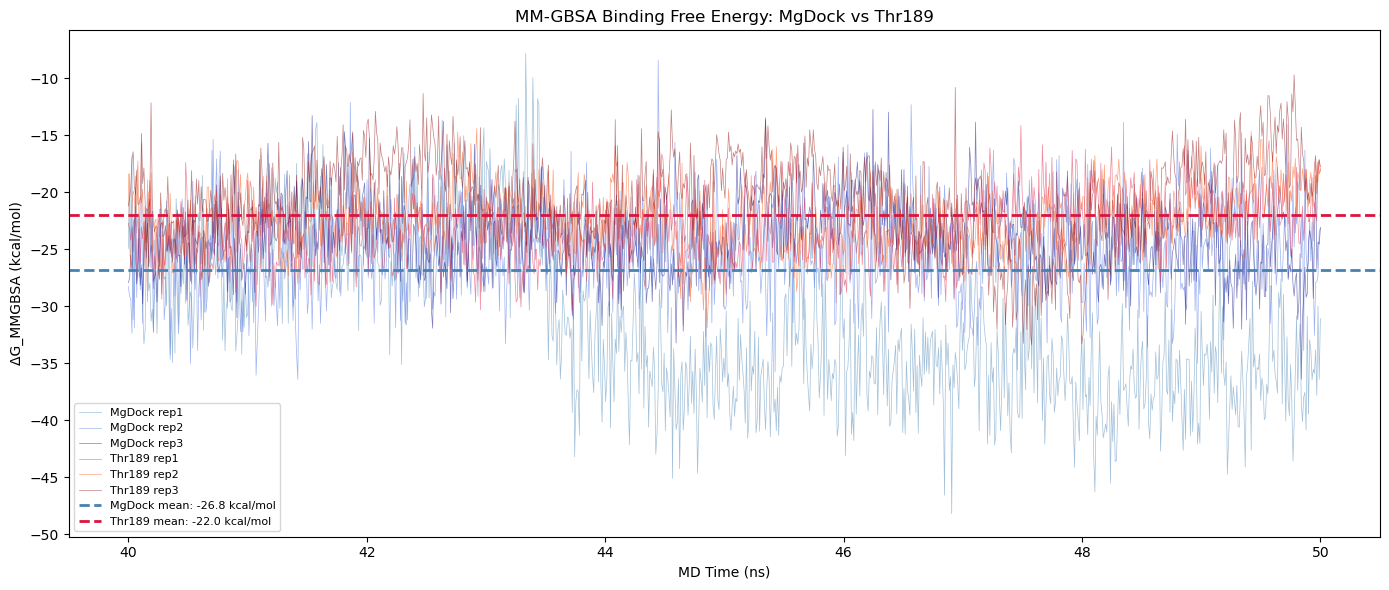


=== Summary ===
MgDock:  -26.83 ± 5.99 kcal/mol
Thr189:  -22.02 ± 3.37 kcal/mol
  MgDock rep1: -31.52 ± 6.93
  MgDock rep2: -25.06 ± 3.99
  MgDock rep3: -23.92 ± 3.17
  Thr189 rep1: -23.22 ± 2.78
  Thr189 rep2: -22.39 ± 2.71
  Thr189 rep3: -20.47 ± 3.89


In [ ]:
import openmm
from openmm import app, unit
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt

def create_context(prmtop_path):
    """Create a persistent context for energy evaluation."""
    prmtop = app.AmberPrmtopFile(prmtop_path)
    system = prmtop.createSystem(
        nonbondedMethod=app.NoCutoff,
        implicitSolvent=app.OBC2,
        implicitSolventSaltConc=0.15*unit.moles/unit.liter,
    )
    integrator = openmm.VerletIntegrator(0.001*unit.picoseconds)
    platform = openmm.Platform.getPlatformByName('CUDA')
    context = openmm.Context(system, integrator, platform)
    return context

def get_energy(context, positions):
    """Evaluate energy using an existing context."""
    context.setPositions(positions)
    state = context.getState(getEnergy=True)
    return state.getPotentialEnergy().value_in_unit(unit.kilocalories_per_mole)

def run_mmgbsa(complex_top, receptor_top, ligand_top, solvated_top, traj_path, start, end):
    """Run MMGBSA for one replica."""
    # Create persistent contexts (only once per replica)
    ctx_complex = create_context(complex_top)
    ctx_receptor = create_context(receptor_top)
    ctx_ligand = create_context(ligand_top)

    n_complex = app.AmberPrmtopFile(complex_top).topology.getNumAtoms()
    n_receptor = app.AmberPrmtopFile(receptor_top).topology.getNumAtoms()

    # Load trajectory, fix PBC, strip solvent
    traj = md.load(traj_path, top=solvated_top)
    traj.image_molecules(inplace=True)
    traj_stripped = traj.atom_slice(list(range(n_complex)))
    traj_last = traj_stripped[start:end]

    print(f"  Processing {traj_last.n_frames} frames...")

    dG_values = []
    for i in range(traj_last.n_frames):
        pos = traj_last.xyz[i]

        E_complex = get_energy(ctx_complex, pos)
        E_receptor = get_energy(ctx_receptor, pos[:n_receptor])
        E_ligand = get_energy(ctx_ligand, pos[n_receptor:n_complex])

        dG = E_complex - E_receptor - E_ligand
        dG_values.append(dG)

        if i % 100 == 0:
            print(f"    Frame {i}/{traj_last.n_frames}: dG = {dG:.2f} kcal/mol")

    del ctx_complex, ctx_receptor, ctx_ligand
    return np.array(dG_values)

# ═══════════════════════════════════════════════════════
# Paths
# ═══════════════════════════════════════════════════════
mg_solvated = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex.prmtop"
mg_complex = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/complex_stripped.prmtop"
mg_receptor = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/receptor.prmtop"
mg_ligand = "/home/mk-avid-workstation/MD Sim/3POV/Dock AD51 Mg/ligand.prmtop"
mg_trajs = [
    "/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_1/trajectory.dcd",
    "/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_3/trajectory.dcd",
    "/home/mk-avid-workstation/MD Sim/DockAD51_Mg_3POV_5/trajectory.dcd",
]

thr_solvated = "/home/mk-avid-workstation/MD Sim/3POV/Thr189_3POV/complex.prmtop"
thr_complex = "/home/mk-avid-workstation/MD Sim/3POV/Thr189_3POV/complex_stripped.prmtop"
thr_receptor = "/home/mk-avid-workstation/MD Sim/3POV/Thr189_3POV/receptor.prmtop"
thr_ligand = "/home/mk-avid-workstation/MD Sim/3POV/Thr189_3POV/ligand.prmtop"
thr_trajs = [f"/home/mk-avid-workstation/MD Sim/thr_3POV_{i}/trajectory.dcd" for i in range(1, 4)]

start = 4112
end = 5112

# ═══════════════════════════════════════════════════════
# Run all 6 replicas
# ═══════════════════════════════════════════════════════
mg_results = []
for rep, traj in enumerate(mg_trajs, 1):
    print(f"\n=== MgDock Replica {rep} ===")
    dG = run_mmgbsa(mg_complex, mg_receptor, mg_ligand, mg_solvated, traj, start, end)
    mg_results.append(dG)
    print(f"  Mean: {dG.mean():.2f} ± {dG.std():.2f} kcal/mol")

thr_results = []
for rep, traj in enumerate(thr_trajs, 1):
    print(f"\n=== Thr189 Replica {rep} ===")
    dG = run_mmgbsa(thr_complex, thr_receptor, thr_ligand, thr_solvated, traj, start, end)
    thr_results.append(dG)
    print(f"  Mean: {dG.mean():.2f} ± {dG.std():.2f} kcal/mol")

# ═══════════════════════════════════════════════════════
# Martin's graph
# ═══════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(14, 6))

colors_mg = ['steelblue', 'royalblue', 'navy']
colors_thr = ['crimson', 'orangered', 'darkred']

for rep, (dG, color) in enumerate(zip(mg_results, colors_mg), 1):
    time_ns = np.linspace(40, 50, len(dG))
    ax.plot(time_ns, dG, color=color, lw=0.5, alpha=0.5, label=f"MgDock rep{rep}")

for rep, (dG, color) in enumerate(zip(thr_results, colors_thr), 1):
    time_ns = np.linspace(40, 50, len(dG))
    ax.plot(time_ns, dG, color=color, lw=0.5, alpha=0.5, label=f"Thr189 rep{rep}")

mg_all = np.concatenate(mg_results)
thr_all = np.concatenate(thr_results)
ax.axhline(mg_all.mean(), color='steelblue', ls='--', lw=2, label=f"MgDock mean: {mg_all.mean():.1f} kcal/mol")
ax.axhline(thr_all.mean(), color='crimson', ls='--', lw=2, label=f"Thr189 mean: {thr_all.mean():.1f} kcal/mol")

ax.set_xlabel("MD Time (ns)")
ax.set_ylabel("ΔG_MMGBSA (kcal/mol)")
ax.set_title("MM-GBSA Binding Free Energy: MgDock vs Thr189")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("mmgbsa_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

# Summary
print(f"\n=== Summary ===")
print(f"MgDock:  {mg_all.mean():.2f} ± {mg_all.std():.2f} kcal/mol")
print(f"Thr189:  {thr_all.mean():.2f} ± {thr_all.std():.2f} kcal/mol")
for rep, dG in enumerate(mg_results, 1):
    print(f"  MgDock rep{rep}: {dG.mean():.2f} ± {dG.std():.2f}")
for rep, dG in enumerate(thr_results, 1):
    print(f"  Thr189 rep{rep}: {dG.mean():.2f} ± {dG.std():.2f}")

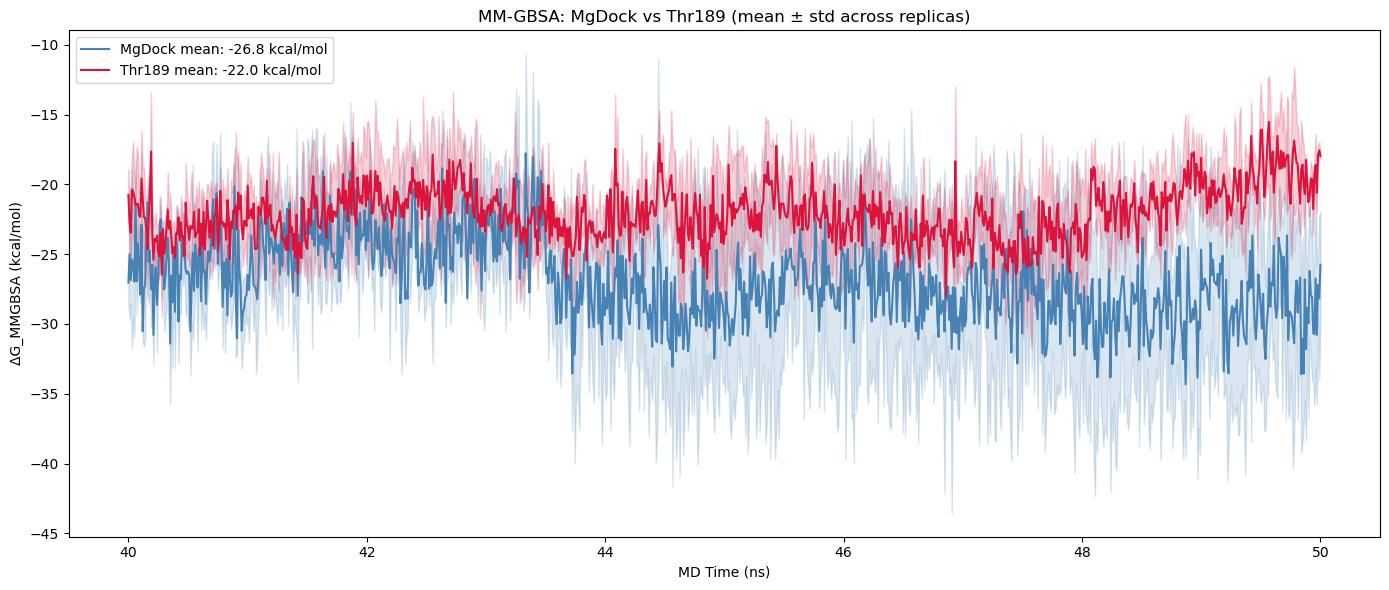

In [ ]:
# Mean ± std across replicas at each time point
mg_stack = np.vstack(mg_results)  # shape (3, 1000)
thr_stack = np.vstack(thr_results)

mg_mean = mg_stack.mean(axis=0)  # mean across 3 replicas per frame
mg_std = mg_stack.std(axis=0)
thr_mean = thr_stack.mean(axis=0)
thr_std = thr_stack.std(axis=0)

time_ns = np.linspace(40, 50, 1000)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(time_ns, mg_mean, color='steelblue', lw=1.5, label=f"MgDock mean: {mg_mean.mean():.1f} kcal/mol")
ax.fill_between(time_ns, mg_mean - mg_std, mg_mean + mg_std, color='steelblue', alpha=0.2)
ax.plot(time_ns, thr_mean, color='crimson', lw=1.5, label=f"Thr189 mean: {thr_mean.mean():.1f} kcal/mol")
ax.fill_between(time_ns, thr_mean - thr_std, thr_mean + thr_std, color='crimson', alpha=0.2)

ax.set_xlabel("MD Time (ns)")
ax.set_ylabel("ΔG_MMGBSA (kcal/mol)")
ax.set_title("MM-GBSA: MgDock vs Thr189 (mean ± std across replicas)")
ax.legend()
plt.tight_layout()
plt.savefig("mmgbsa_mean_comparison.png", dpi=300, bbox_inches='tight')
plt.show()